# **Применение методов машинного обучения без учителя для кластеризации растров в среде Google Earth Engine с целью выявления пространственных аномалий и оптимизации объема данных**

## **Введение**

В предыдущем блокноте мы классифицировали земной покров: модели обучались на размеченных примерах и относили каждый пиксель к одному из заранее заданных классов. В этом блокноте мы рассмотрим другой подход — **кластеризацию**: алгоритм получает только сами пиксели, без меток, и сам находит в них группы похожих значений.

**Основные задачи:**
- Понять, чем кластеризация отличается от классификации и в каких задачах она нужна
- Разобраться в работе алгоритма K-средних (K-means) на реальных пикселях спутникового снимка
- Научиться выбирать признаки и число кластеров
- Кластеризовать снимок Sentinel-2 и дать кластерам осмысленные названия
- Найти с помощью кластеризации объекты, которых нет среди заданных классов готовых карт
- Применить кластеризацию для сжатия изображений и правильно сохранить результат

### **Основные определения**

**Обучение без учителя** — класс методов машинного обучения, которые работают с данными без правильных ответов (меток) и ищут в них структуру: группы, закономерности, необычные объекты.

**Кластер** — группа объектов, которые похожи друг на друга сильнее, чем на объекты других групп. В нашем случае объект — это пиксель снимка.

**Признаки** — числа, которыми описан каждый объект. Для пикселя спутникового снимка это значения отражения в спектральных каналах и рассчитанные по ним индексы.

**Пространство признаков** — пространство, в котором каждый объект является точкой с координатами, равными его признакам. Пиксель с шестью каналами — точка в шестимерном пространстве.

**Центроид** — «центр» кластера: точка, координаты которой равны средним значениям признаков всех объектов кластера.

---

## **Раздел 1. Подготовка данных в Google Earth Engine**

### **1.1. Настройка рабочей среды**

In [ ]:
%%capture
!pip install -U geemap geedim rasterio scikit-learn scikit-image

In [ ]:
# Импорт основных библиотек для работы
import os
import io
import time
import urllib.request

import ee                        # Google Earth Engine
import geemap                    # Интерактивные карты для GEE
import numpy as np               # Работа с массивами
import pandas as pd              # Работа с таблицами
import rasterio                  # Чтение экспортированных GeoTIFF
import matplotlib.pyplot as plt  # Построение графиков
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from PIL import Image            # Работа с изображениями и сохранение палитровых PNG
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

%config InlineBackend.figure_format = 'jpeg'  # рисунки с фотографиями компактнее в JPEG

**Пояснение используемых библиотек:**
- `ee` и `geemap` — доступ к Google Earth Engine и интерактивные карты
- `rasterio` — чтение геопривязанных растров, экспортированных из GEE
- `scikit-learn` — алгоритм K-средних (`KMeans`), стандартизация признаков (`StandardScaler`) и коэффициент силуэта (`silhouette_score`)
- `scikit-image` — метрики качества изображений PSNR и SSIM
- `PIL` — сохранение изображений в палитровом формате PNG

### **1.2. Аутентификация и инициализация**

Перед началом работы с geemap и Google Earth Engine необходимо:

- **Зарегистрировать аккаунт Google Earth Engine**: Перейдите на [https://code.earthengine.google.com/register](https://code.earthengine.google.com/register) для создания аккаунта GEE. После регистрации нужно настроить проект Google Cloud и активировать API Earth Engine, следуя инструкциям [здесь](https://docs.google.com/document/d/1ZGSmrNm6_baqd8CHt33kIBWOlvkh-HLr46bODgJN1h0/edit?usp=sharing). GEE бесплатен для [некоммерческого и исследовательского использования](https://earthengine.google.com/noncommercial).

- **Проверить аутентификацию API**: Чтобы убедиться в правильности настройки аккаунта Earth Engine, запустите [этот тестовый блокнот](https://colab.research.google.com/github/gee-community/geemap/blob/master/docs/notebooks/geemap_colab.ipynb) в Google Colab.

In [ ]:
# Аутентификация в Google Earth Engine
# При первом запуске откроется окно авторизации через Google аккаунт
ee.Authenticate()

# Инициализация Earth Engine с указанием проекта
# Важно: замените 'seraphic-effect-413810' на имя вашего проекта в Google Cloud
ee.Initialize(project='seraphic-effect-413810')

### **1.3. Выбор области интереса на карте**

In [ ]:
# Интерактивная карта с инструментами рисования
Map = geemap.Map(center=[55.98, 37.51], zoom=11)
Map.add_basemap('Esri.WorldImagery')
Map.add_draw_control()
Map

Map(center=[55.98, 37.51], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

**Функционал интерактивной карты:**
- Инструменты рисования позволяют выделить полигон или прямоугольник; выбранная область сохраняется как `Map.user_roi`
- Если область не нарисована, используется участок по умолчанию — около 14×13 км у Клязьминского водохранилища: водохранилище и реки, леса, жилая и промышленная застройка, аэропорт Шереметьево
- Для экспорта с разрешением 10 м удобны участки размером 10–20 км

In [ ]:
def get_user_roi():
    """Нарисованная на карте область или участок по умолчанию."""
    if Map.user_roi is not None:
        return Map.user_roi
    return ee.Geometry.Rectangle([37.40, 55.92, 37.62, 56.04])

roi = get_user_roi()
print(f'Площадь области интереса: {roi.area(maxError=1).getInfo() / 1e6:.1f} км²')

Площадь области интереса: 182.6 км²


### **1.4. Летний композит Sentinel-2**

Как и в предыдущем блокноте, используем снимки Sentinel-2 уровня 2A за лето, маскируем облака и их тени по каналу SCL и строим медианный композит. Для кластеризации возьмём шесть каналов: синий (B2), зелёный (B3), красный (B4), ближний инфракрасный (B8) и два коротковолновых инфракрасных (B11, B12).

In [ ]:
YEAR = 2024
BANDS = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']

def mask_clouds(image):
    """Маска облаков и теней по каналу SCL и перевод отражения в диапазон 0-1."""
    scl = image.select('SCL')
    mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
    return image.select(BANDS).updateMask(mask).divide(10000)

collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
              .filterBounds(roi)
              .filterDate(f'{YEAR}-06-01', f'{YEAR}-09-01')
              .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
              .map(mask_clouds))
composite = collection.median().clip(roi)
print(f'Снимков в композите: {collection.size().getInfo()}')

map_composite = geemap.Map()
map_composite.add_basemap('Esri.WorldImagery')
map_composite.centerObject(roi, 12)
map_composite.addLayer(composite, {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 0.3, 'gamma': 1.4}, f'Sentinel-2, лето {YEAR}')
map_composite

Снимков в композите: 41


Map(center=[55.98001793820693, 37.51000000000046], controls=(WidgetControl(options=['position', 'transparent_b…

### **1.5. Карта Dynamic World для сравнения**

Чтобы понять, что означают найденные кластеры, сравним их с готовой картой классификации Dynamic World того же лета: наиболее частый класс (мода) в каждом пикселе.

In [ ]:
DW_NAMES = ['Вода', 'Деревья', 'Трава', 'Затопл. растительность', 'Культуры',
            'Кустарники', 'Застройка', 'Голая земля', 'Снег и лед']
DW_COLORS = ['#419bdf', '#397d49', '#88b053', '#7a87c6', '#e49635',
             '#dfc35a', '#c4281b', '#a59b8f', '#b39fe1']

dynamic_world = (ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1')
                 .filterBounds(roi)
                 .filterDate(f'{YEAR}-06-01', f'{YEAR}-09-01')
                 .select('label')
                 .mode()
                 .clip(roi))

### **1.6. Экспорт и загрузка растров**

Растры экспортируются в метрической проекции UTM с пикселем 10 м и загружаются плитками 256×256 пикселей (функции из предыдущего блокнота). Карта Dynamic World сохраняется с типом `int16`: при типе `uint8` значение 0 используется как «нет данных» и совпало бы с классом «Вода». Если экспорт идёт слишком долго, увеличьте `SCALE` до 20–30 м.

In [ ]:
SCALE = 10  # размер пикселя, м

def utm_crs(region):
    """Код EPSG зоны UTM для центра области."""
    lon, lat = region.centroid(maxError=1).coordinates().getInfo()
    return f'EPSG:{(32600 if lat >= 0 else 32700) + int((lon + 180) // 6) + 1}'

def export_georeferenced_raster(image, region, filename, scale=10, dtype='float32', tile_size=256):
    """Экспорт в GeoTIFF в проекции UTM с загрузкой плитками."""
    geemap.download_ee_image(image=image, filename=filename, region=region, scale=scale,
                             crs=utm_crs(region), dtype=dtype, max_tile_dim=tile_size)
    return filename

os.makedirs('data', exist_ok=True)
export_georeferenced_raster(composite, roi, 'data/sentinel2.tif', scale=SCALE)
export_georeferenced_raster(dynamic_world, roi, 'data/dynamic_world.tif', scale=SCALE, dtype='int16')

  0%|          |0/216 tiles [00:00<?]

  0%|          |0/36 tiles [00:00<?]

'data/dynamic_world.tif'

Размер растра: 1402×1366 пикселей, пиксель 100 м², пикселей с данными: 1,836,417


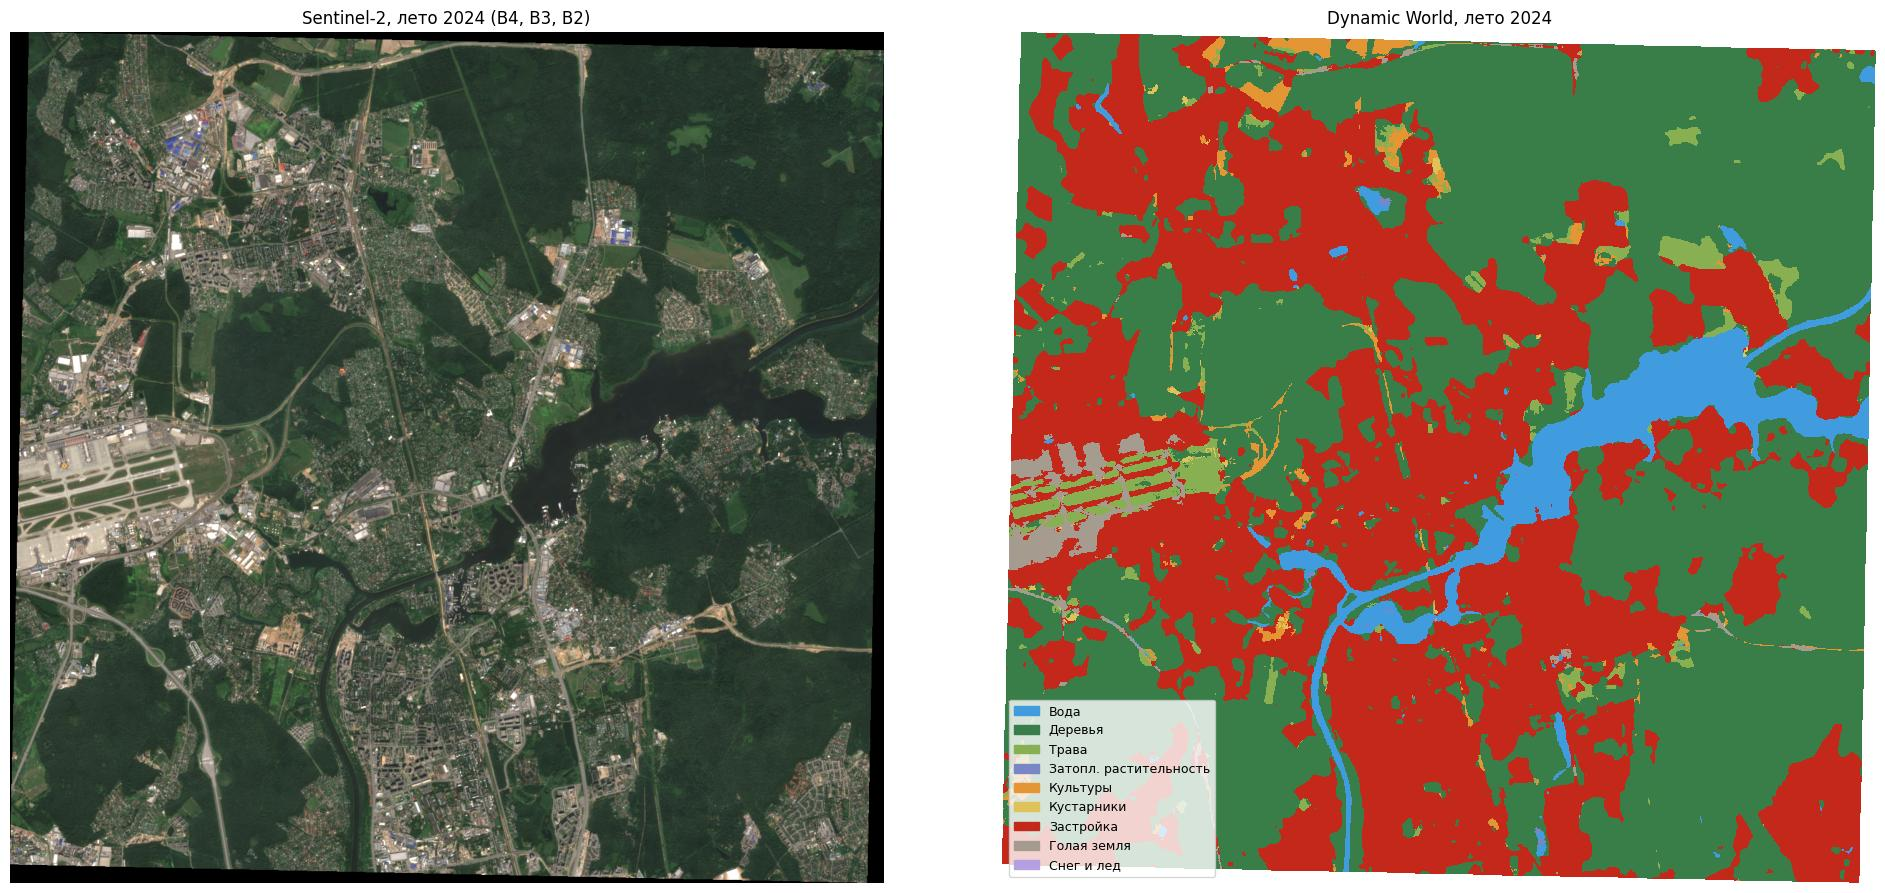

In [ ]:
with rasterio.open('data/sentinel2.tif') as src:
    bands = src.read().astype('float32')        # (каналы, строки, столбцы)
    PIXEL_AREA_HA = src.res[0] * src.res[1] / 10000
with rasterio.open('data/dynamic_world.tif') as src:
    dw = src.read(1)

valid = np.isfinite(bands).all(axis=0) & (dw >= 0)   # пиксели с данными
H, W = valid.shape
rgb = np.clip(np.nan_to_num(np.dstack([bands[2], bands[1], bands[0]]), posinf=0, neginf=0) / 0.3, 0, 1) ** (1 / 1.4)

print(f'Размер растра: {W}×{H} пикселей, пиксель {PIXEL_AREA_HA * 10000:.0f} м², пикселей с данными: {valid.sum():,}')
fig, axes = plt.subplots(1, 2, figsize=(20, 9))
axes[0].imshow(rgb)
axes[0].set_title(f'Sentinel-2, лето {YEAR} (B4, B3, B2)')
axes[1].imshow(np.ma.masked_less(dw, 0), cmap=ListedColormap(DW_COLORS), vmin=-0.5, vmax=8.5, interpolation='nearest')
axes[1].set_title(f'Dynamic World, лето {YEAR}')
axes[1].legend(handles=[Patch(color=col, label=name) for col, name in zip(DW_COLORS, DW_NAMES)], loc='lower left', fontsize=9)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### **Выводы по разделу 1:**

1. Подготовка данных повторяет шаги предыдущего блокнота: область интереса, летний композит Sentinel-2 с маской облаков, экспорт в метрической проекции
2. Каждый пиксель композита описывается шестью значениями отражения — это и есть его признаки для кластеризации
3. Карта Dynamic World используется не для обучения, а только для того, чтобы понять смысл найденных кластеров

---

## **Раздел 2. Теория кластеризации**

### **2.1. Классификация и кластеризация**

В предыдущем блокноте мы решали задачу **классификации**: у нас была эталонная карта ESA WorldCover, мы брали из неё примеры пикселей с известными классами, обучали модель и затем относили к этим классам все пиксели снимка. Модель могла выдать только те классы, которые были в эталоне.

**Кластеризация** решает другую задачу. Алгоритм получает только значения пикселей и делит их на группы так, чтобы пиксели внутри группы были похожи, а пиксели разных групп — различались. Заранее заданных классов нет: алгоритм сообщает лишь «эти пиксели похожи между собой», а что означает каждая группа, решает исследователь.

| | **Классификация** | **Кластеризация** |
|---|---|---|
| Тип обучения | С учителем | Без учителя |
| Что нужно на входе | Признаки и правильные ответы (метки) | Только признаки |
| Результат | Номер одного из заранее заданных классов | Номер найденной группы (кластера), без названия |
| На какой вопрос отвечает | «К какому из известных классов относится пиксель?» | «Какие группы похожих пикселей есть в данных?» |
| Откуда берётся смысл | Из эталонной разметки | Из интерпретации исследователем |
| Может ли найти новый класс | Нет: только классы из разметки | Да: любую группу, которая заметно отличается от остальных |

Последняя строка таблицы — главное, ради чего используют кластеризацию: она может показать группу объектов, о существовании которой мы не знали и которую поэтому не могли заложить в классы. Именно это мы увидим в разделе 5.

### **2.2. Пиксель как точка в пространстве признаков**

Чтобы понять, как алгоритм находит группы, представим пиксели точками. Возьмём только два признака — отражение в красном (B4) и ближнем инфракрасном (B8) каналах — и нанесём случайные пиксели снимка на плоскость. Цветом покажем класс Dynamic World, чтобы увидеть, где на этой плоскости лежат разные типы покрова.

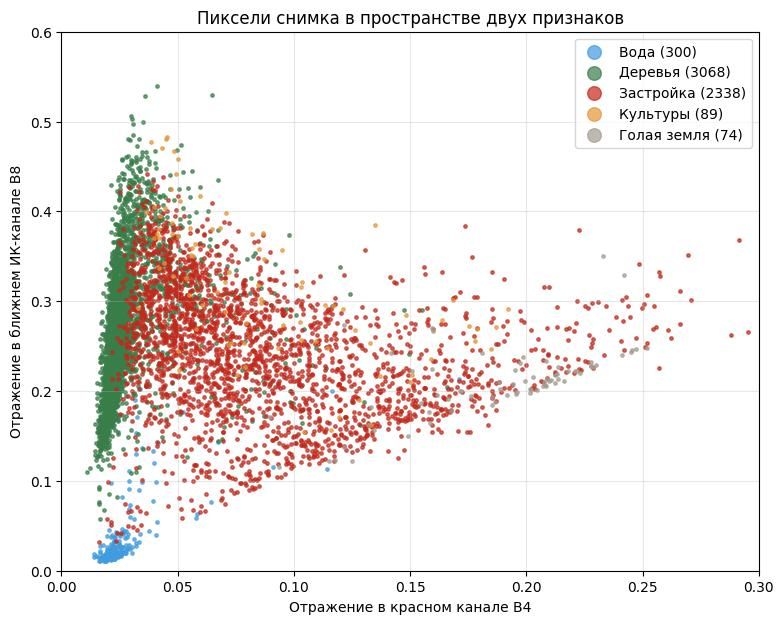

In [ ]:
rng = np.random.default_rng(42)
idx = rng.choice(np.flatnonzero(valid), 6000, replace=False)  # случайные пиксели с данными
red, nir, classes = bands[2].ravel()[idx], bands[3].ravel()[idx], dw.ravel()[idx]

plt.figure(figsize=(9, 7))
for k, name in [(0, 'Вода'), (1, 'Деревья'), (6, 'Застройка'), (4, 'Культуры'), (7, 'Голая земля')]:
    m = classes == k
    plt.scatter(red[m], nir[m], s=6, color=DW_COLORS[k], label=f'{name} ({m.sum()})', alpha=0.7)
plt.xlabel('Отражение в красном канале B4')
plt.ylabel('Отражение в ближнем ИК-канале B8')
plt.xlim(0, 0.3)
plt.ylim(0, 0.6)
plt.legend(markerscale=4)
plt.grid(True, alpha=0.3)
plt.title('Пиксели снимка в пространстве двух признаков')
plt.show()

Разные типы покрова занимают на плоскости разные области. Вода — плотное скопление в левом нижнем углу: она слабо отражает и красный, и ближний ИК. Деревья образуют вытянутый вертикальный «столб» слева: красный свет поглощается хлорофиллом, а ближний ИК листва отражает сильно. Застройка рассеяна широким облаком правее и ниже — у искусственных покрытий отражение в красном выше, а в ближнем ИК ниже, чем у растительности. Голая земля лежит у правого края облака, где отражение в красном наибольшее.

На этом и основана кластеризация: если похожие объекты образуют на графике сгущения, алгоритм может найти эти сгущения автоматически, не зная, какой класс у каждой точки. В реальной задаче признаков больше двух (у нас шесть каналов), нарисовать такое пространство уже нельзя, но расстояния между точками в нём считаются так же.

### **2.3. Алгоритм K-средних (K-means)**

**K-средних** — самый распространённый алгоритм кластеризации. Он делит объекты на заранее заданное число групп $K$ так, чтобы каждый объект был как можно ближе к центру (центроиду) своей группы.

#### **Мера похожести: евклидово расстояние**

Похожесть двух пикселей измеряется расстоянием между ними в пространстве признаков. Для пикселей $\mathbf{x}$ и $\mathbf{y}$ с $n$ признаками:

$$d(\mathbf{x}, \mathbf{y}) = \sqrt{\sum_{j=1}^{n} (x_j - y_j)^2}$$

Это обычное расстояние «по прямой», как между точками на плоскости, только в $n$-мерном пространстве. Чем меньше расстояние, тем более похожи значения отражения пикселей во всех каналах.

#### **Что минимизирует алгоритм**

Алгоритм ищет такое разбиение на $K$ кластеров и такие центроиды $\boldsymbol{\mu}_1, \dots, \boldsymbol{\mu}_K$, при которых минимальна **сумма квадратов расстояний** от каждого объекта до центроида его кластера:

$$J = \sum_{k=1}^{K} \sum_{\mathbf{x} \in C_k} \lVert \mathbf{x} - \boldsymbol{\mu}_k \rVert^2$$

где $C_k$ — множество объектов $k$-го кластера. Эту величину называют **инерцией** (inertia) или внутрикластерной суммой квадратов. Чем она меньше, тем плотнее объекты собраны вокруг своих центроидов.

#### **Шаги алгоритма**

1. **Инициализация.** Выбираем $K$ начальных центроидов — например, $K$ случайных объектов из данных.
2. **Назначение.** Каждый объект относим к кластеру ближайшего центроида.
3. **Пересчёт центроидов.** Новый центроид каждого кластера — среднее значение признаков всех его объектов: $\boldsymbol{\mu}_k = \frac{1}{|C_k|}\sum_{\mathbf{x} \in C_k} \mathbf{x}$.
4. **Повторение.** Повторяем шаги 2 и 3, пока назначения объектов перестанут меняться (или центроиды сдвигаются меньше заданного порога).

Каждый из шагов 2 и 3 может только уменьшить инерцию $J$: при назначении каждый объект переходит к более близкому центроиду, а среднее — это точка, сумма квадратов расстояний до которой от объектов кластера минимальна. Поэтому алгоритм всегда останавливается. Но останавливается он в **локальном** минимуме: результат зависит от начальных центроидов.

#### **Инициализация k-means++**

Чтобы уменьшить зависимость от случайного начала, используют инициализацию **k-means++**: первый центроид выбирается случайно, а каждый следующий — тоже случайно, но с вероятностью, пропорциональной квадрату расстояния до ближайшего уже выбранного центроида. Так начальные центроиды оказываются разнесены по данным. Кроме того, алгоритм запускают несколько раз с разными начальными центроидами и оставляют лучший результат (параметр `n_init`). В `scikit-learn` k-means++ используется по умолчанию.

### **2.4. Работа алгоритма по шагам на пикселях снимка**

Проследим работу алгоритма на тех же пикселях в пространстве двух признаков (B4 и B8). Реализуем K-средних вручную в несколько строк и запомним положение центроидов и разбиение на каждой итерации. Начальные центроиды для наглядности выберем случайно, без k-means++.

In [ ]:
points = np.column_stack([red, nir])  # 6000 пикселей × 2 признака
K = 4
centroids = points[rng.choice(len(points), K, replace=False)]  # случайные начальные центроиды

history = []
for iteration in range(50):
    # Шаг 2: расстояния от каждой точки до каждого центроида и номер ближайшего
    distances = np.linalg.norm(points[:, None, :] - centroids[None, :, :], axis=2)
    labels = distances.argmin(axis=1)
    inertia = (distances.min(axis=1) ** 2).sum()
    history.append((centroids.copy(), labels, inertia))
    # Шаг 3: новые центроиды — средние точек каждого кластера
    new_centroids = np.array([points[labels == k].mean(axis=0) for k in range(K)])
    if np.allclose(new_centroids, centroids):
        break
    centroids = new_centroids

print(f'Алгоритм сошёлся за {len(history)} итераций')

Алгоритм сошёлся за 34 итераций


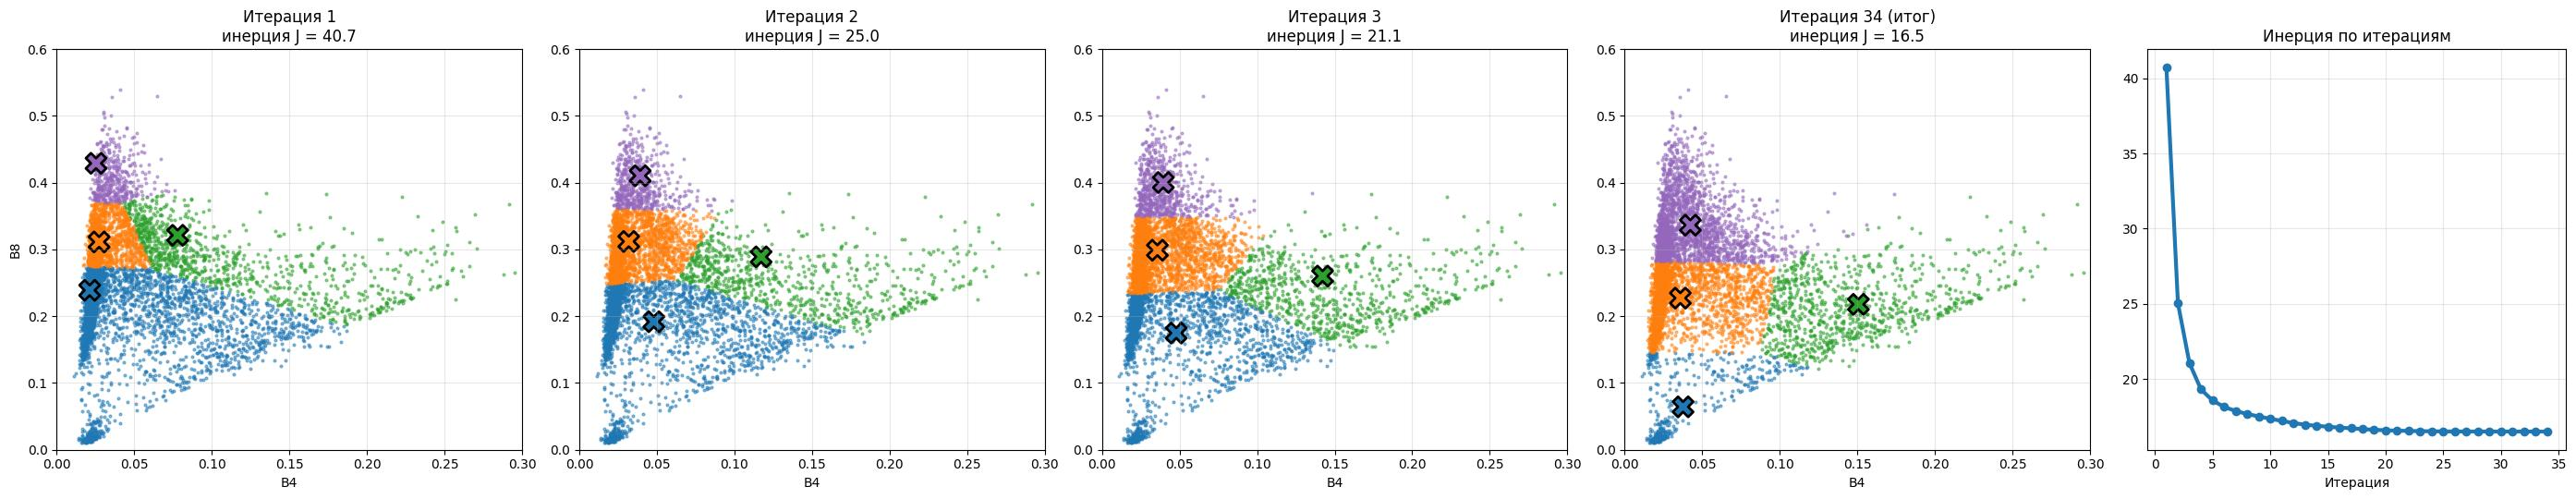

In [ ]:
colors4 = ['tab:blue', 'tab:green', 'tab:orange', 'tab:purple']
shown = [0, 1, 2, len(history) - 1]
fig, axes = plt.subplots(1, 5, figsize=(28, 5.5), gridspec_kw={'width_ratios': [1, 1, 1, 1, 0.9]})
for ax, i in zip(axes, shown):
    cent, lab, inertia = history[i]
    for k in range(K):
        ax.scatter(points[lab == k, 0], points[lab == k, 1], s=4, color=colors4[k], alpha=0.5)
    ax.scatter(cent[:, 0], cent[:, 1], s=250, c=colors4, marker='X', edgecolor='black', linewidth=2)
    ax.set_title(f'Итерация {i + 1}' + (' (итог)' if i == len(history) - 1 else '') + f'\nинерция J = {inertia:.1f}')
    ax.set_xlim(0, 0.3)
    ax.set_ylim(0, 0.6)
    ax.set_xlabel('B4')
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel('B8')
axes[4].plot(range(1, len(history) + 1), [hst[2] for hst in history], 'o-', linewidth=3)
axes[4].set_title('Инерция по итерациям')
axes[4].set_xlabel('Итерация')
axes[4].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Алгоритм сошёлся за 34 итерации, но почти всё уменьшение инерции произошло на первых пяти: с 40,7 на первой итерации до 21,1 на третьей и 16,5 в итоге. Дальнейшие итерации лишь немного сдвигают границы между кластерами.

Обратите внимание на итоговое разбиение. Плотный «столб» растительности разделился на два кластера — с более высоким и более низким отражением в ближнем ИК, облако застройки и почвы с высоким отражением в красном образовало третий кластер. А вода, хотя и хорошо отделена на графике, своего центроида не получила и вошла в один кластер с тёмными участками застройки: при $K = 4$ алгоритму выгоднее «потратить» центроиды на большие облака точек, так как они вносят основной вклад в сумму квадратов расстояний. Это важное свойство K-средних: кластеры отражают устройство облака точек, а не смысловые классы, и малочисленные группы получают собственный кластер только при достаточно большом $K$.

#### **Ещё раз простыми словами о работе алгоритма:**

1. **Начало**: ставим $K$ «флажков» (центроидов) в случайные точки данных.
2. **Разделение данных**: каждый пиксель «подходит» к ближайшему флажку — так данные разбиваются на $K$ групп.
3. **Перенос флажков**: каждый флажок переносим в центр своей группы — в точку со средними значениями признаков.
4. **Повторение**: после переноса флажков часть пикселей оказывается ближе к другому флажку и переходит в другую группу; снова переносим флажки.
5. **Завершение**: когда пиксели перестают переходить между группами, флажки больше не двигаются — алгоритм закончен.

### **2.5. Признаки и их масштабирование**

Алгоритм сравнивает пиксели только по расстоянию, поэтому результат определяется тем, какие признаки мы ему дали и в каком масштабе. Для спутникового снимка естественные признаки — значения отражения в каналах. К ним можно добавить спектральные индексы: NDVI хорошо отделяет растительность, NDWI — воду.

Проблема в том, что признаки имеют разный разброс значений. Если один признак меняется в пределах десятых долей, а другой — в пределах сотых, то расстояние почти целиком определяется первым признаком, а второй практически не влияет на результат. Посмотрим на стандартные отклонения наших признаков.

In [ ]:
pixels = bands[:, valid].T                                  # (пиксели, 6 каналов)
B2, B3, B4, B8, B11, B12 = pixels.T
ndvi = (B8 - B4) / (B8 + B4)
ndwi = (B3 - B8) / (B3 + B8)
FEATURE_NAMES = BANDS + ['NDVI', 'NDWI']
features = np.column_stack([pixels, ndvi, ndwi])

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)            # (x - среднее) / стандартное отклонение

pd.DataFrame({'Среднее': features.mean(axis=0), 'Стандартное отклонение': features.std(axis=0),
              'Ст. откл. после стандартизации': features_scaled.std(axis=0)}, index=FEATURE_NAMES).round(3)

,Среднее,Стандартное отклонение,Ст. откл. после стандартизации
B2,0.050,0.038,0.999
B3,0.065,0.041,0.999
B4,0.056,0.051,1.000
B8,0.249,0.087,0.999
B11,0.158,0.060,0.999
B12,0.101,0.061,0.999
NDVI,0.615,0.286,1.000
NDWI,-0.557,0.252,1.000


Стандартные отклонения каналов отражения лежат в пределах 0,04–0,09, а у индексов NDVI и NDWI — 0,29 и 0,25, то есть в 3–7 раз больше. Без масштабирования расстояние между пикселями определялось бы в основном индексами, а различия, например, в синем или коротковолновом ИК-канале почти не учитывались бы. После стандартизации стандартное отклонение каждого признака равно 1.

**Стандартизация** приводит каждый признак к нулевому среднему и единичному стандартному отклонению:

$$z = \frac{x - \bar{x}}{\sigma}$$

После неё каждый признак вносит в расстояние сопоставимый вклад, и алгоритм учитывает все каналы и индексы, а не только самые «размашистые». Если все признаки измерены в одних единицах и имеют близкий разброс (например, только каналы отражения), стандартизация не обязательна; при смешивании каналов и индексов она нужна.

### **2.6. Выбор числа кластеров**

Число кластеров $K$ алгоритм не определяет сам — его задаёт исследователь. Для подсказки используют две величины.

**Метод локтя.** Инерция $J$ всегда уменьшается с ростом $K$ (при $K$, равном числу пикселей, она равна нулю), поэтому её минимум бесполезен. Смотрят на форму кривой: пока $K$ меньше числа естественных групп, добавление кластера сильно уменьшает инерцию; после этого — заметно слабее. Точка перегиба кривой («локоть») подсказывает разумное $K$.

**Коэффициент силуэта.** Для каждого объекта вычисляются $a$ — среднее расстояние до объектов своего кластера и $b$ — среднее расстояние до объектов ближайшего чужого кластера:

$$s = \frac{b - a}{\max(a, b)}$$

Значение $s$ близко к 1, если объект плотно окружён «своими» и далёк от «чужих», около 0 — если он на границе кластеров, и отрицательно, если он ближе к чужому кластеру. Средний силуэт по всем объектам характеризует качество разбиения в целом. Расчёт силуэта требует расстояний между всеми парами объектов, поэтому его считают на подвыборке.

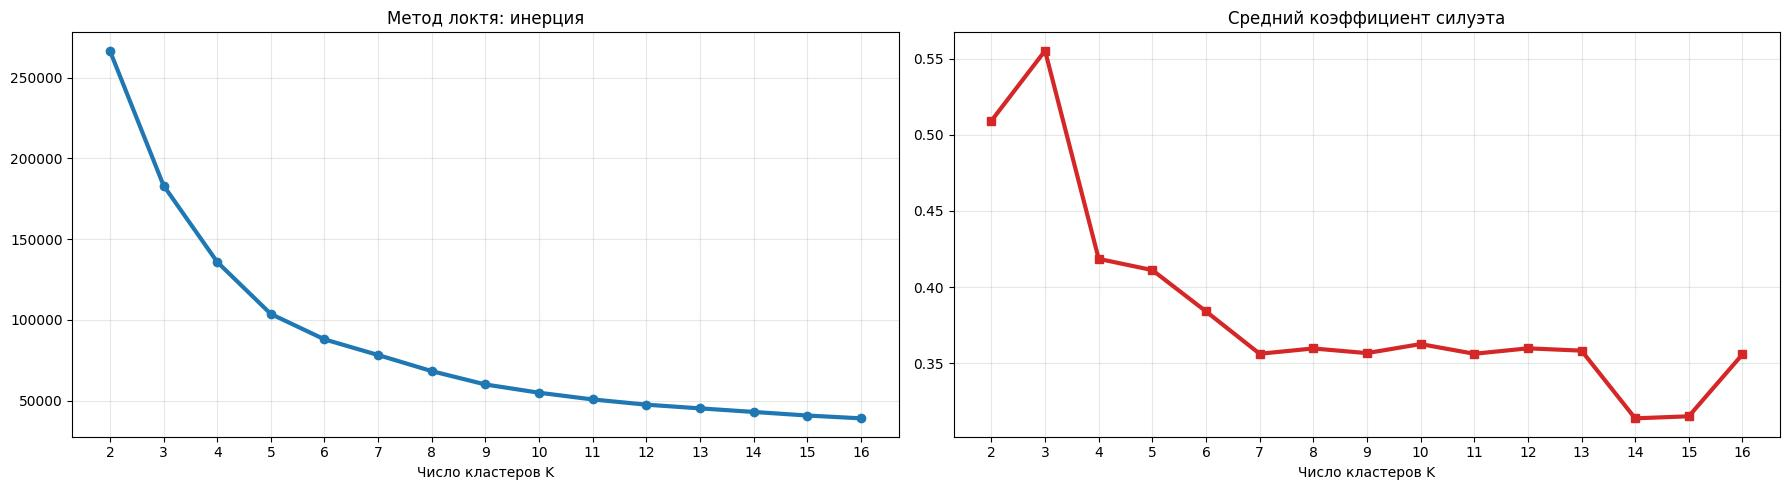

In [ ]:
sample = rng.choice(len(features_scaled), 60000, replace=False)   # подвыборка для обучения
small = sample[:6000]                                               # подвыборка для силуэта

ks = list(range(2, 17))
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=3, random_state=0).fit(features_scaled[sample])
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(features_scaled[small], km.predict(features_scaled[small])))

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
axes[0].plot(ks, inertias, 'o-', linewidth=3)
axes[0].set_title('Метод локтя: инерция')
axes[1].plot(ks, silhouettes, 's-', color='tab:red', linewidth=3)
axes[1].set_title('Средний коэффициент силуэта')
for ax in axes:
    ax.set_xlabel('Число кластеров K')
    ax.set_xticks(ks)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Инерция резко падает до $K = 5$, после чего снижается заметно медленнее — «локоть» находится в районе $K = 5–6$. Коэффициент силуэта максимален при $K = 3$ (0,55): разбиение на три крупные группы (вода, растительность, застройка) самое чёткое. При $K$ от 7 до 13 силуэт держится примерно на одном уровне (около 0,36).

Метрики показывают, сколько групп снимок содержит «в крупном». Но наша цель — увидеть и небольшие группы, поэтому дальше возьмём $K = 12$: силуэт при этом не хуже, чем при $K = 7–11$, а детализация больше. Это типичная ситуация: число кластеров выбирают не только по метрикам, но и по задаче.

### **2.7. Преимущества и недостатки K-средних**

**Преимущества:**
- Простота реализации и понимания
- Масштабируемость до огромных наборов данных: миллионы пикселей обрабатываются за секунды
- Быстрое отнесение новых объектов к найденным кластерам: достаточно найти ближайший центроид
- Не требует разметки — работает там, где эталонных карт нет или они устарели

**Недостатки:**
- Не гарантируется достижение глобального минимума; результат зависит от начальных центроидов (частично решается k-means++ и несколькими запусками)
- Число кластеров необходимо задать заранее
- Чувствительность к выбросам и к масштабу признаков
- Предполагает кластеры примерно «круглой» формы и сопоставимого разброса
- **Для снимков:** кластеры — это группы по спектру, а не по смыслу: разные объекты с похожим спектром (тёмная крыша и тень) попадут в один кластер, а один объект с неоднородным спектром (жилой квартал с деревьями) разделится на несколько
- **Для снимков:** пространственное соседство не учитывается — каждый пиксель кластеризуется отдельно

### **Выводы по разделу 2:**

1. **Кластеризация** делит объекты на группы похожих без использования меток; смысл группам придаёт исследователь
2. **K-средних** чередует два шага — отнесение объектов к ближайшему центроиду и пересчёт центроидов как средних — и минимизирует сумму квадратов расстояний до центроидов
3. **Признаки** нужно приводить к сопоставимому масштабу, иначе расстояние определяется одним признаком
4. **Число кластеров** подсказывают метод локтя и коэффициент силуэта, но окончательный выбор зависит от цели: для обзора хватает нескольких крупных групп, для поиска редких объектов кластеров нужно больше

---

## **Раздел 3. Кластеризация снимка и интерпретация кластеров**

### **3.1. Кластеризация композита**

Кластеризуем все пиксели снимка по восьми стандартизированным признакам (шесть каналов, NDVI и NDWI). Возьмём $K = 12$ — больше, чем подсказывают метрики: нас интересуют не только крупные группы, но и небольшие, которые могут оказаться неожиданными. Обучать алгоритм на всех почти двух миллионах пикселей не нужно: центроиды находятся по случайной подвыборке, а затем каждый пиксель снимка относится к ближайшему центроиду методом `predict`.

**Параметры KMeans:**
- `n_clusters` — число кластеров $K$
- `n_init` — сколько раз запустить алгоритм с разными начальными центроидами (остаётся запуск с наименьшей инерцией)
- `init` — способ инициализации, по умолчанию `'k-means++'`
- `random_state` — начальное значение генератора случайных чисел для воспроизводимости

In [ ]:
K = 12
kmeans = KMeans(n_clusters=K, n_init=5, random_state=0).fit(features_scaled[sample])

cluster_map = np.full((H, W), -1)
cluster_map[valid] = kmeans.predict(features_scaled)       # номер кластера каждого пикселя

areas = pd.Series(np.bincount(cluster_map[valid], minlength=K) * PIXEL_AREA_HA, name='Площадь, га')
print(areas.round(1).to_string())

0     1749.9
1      739.2
2      769.8
3      460.1
4     2178.8
5      760.2
6     3172.1
7     1073.8
8     4306.8
9     1434.5
10      40.2
11    1678.8


### **3.2. Карта кластеров**

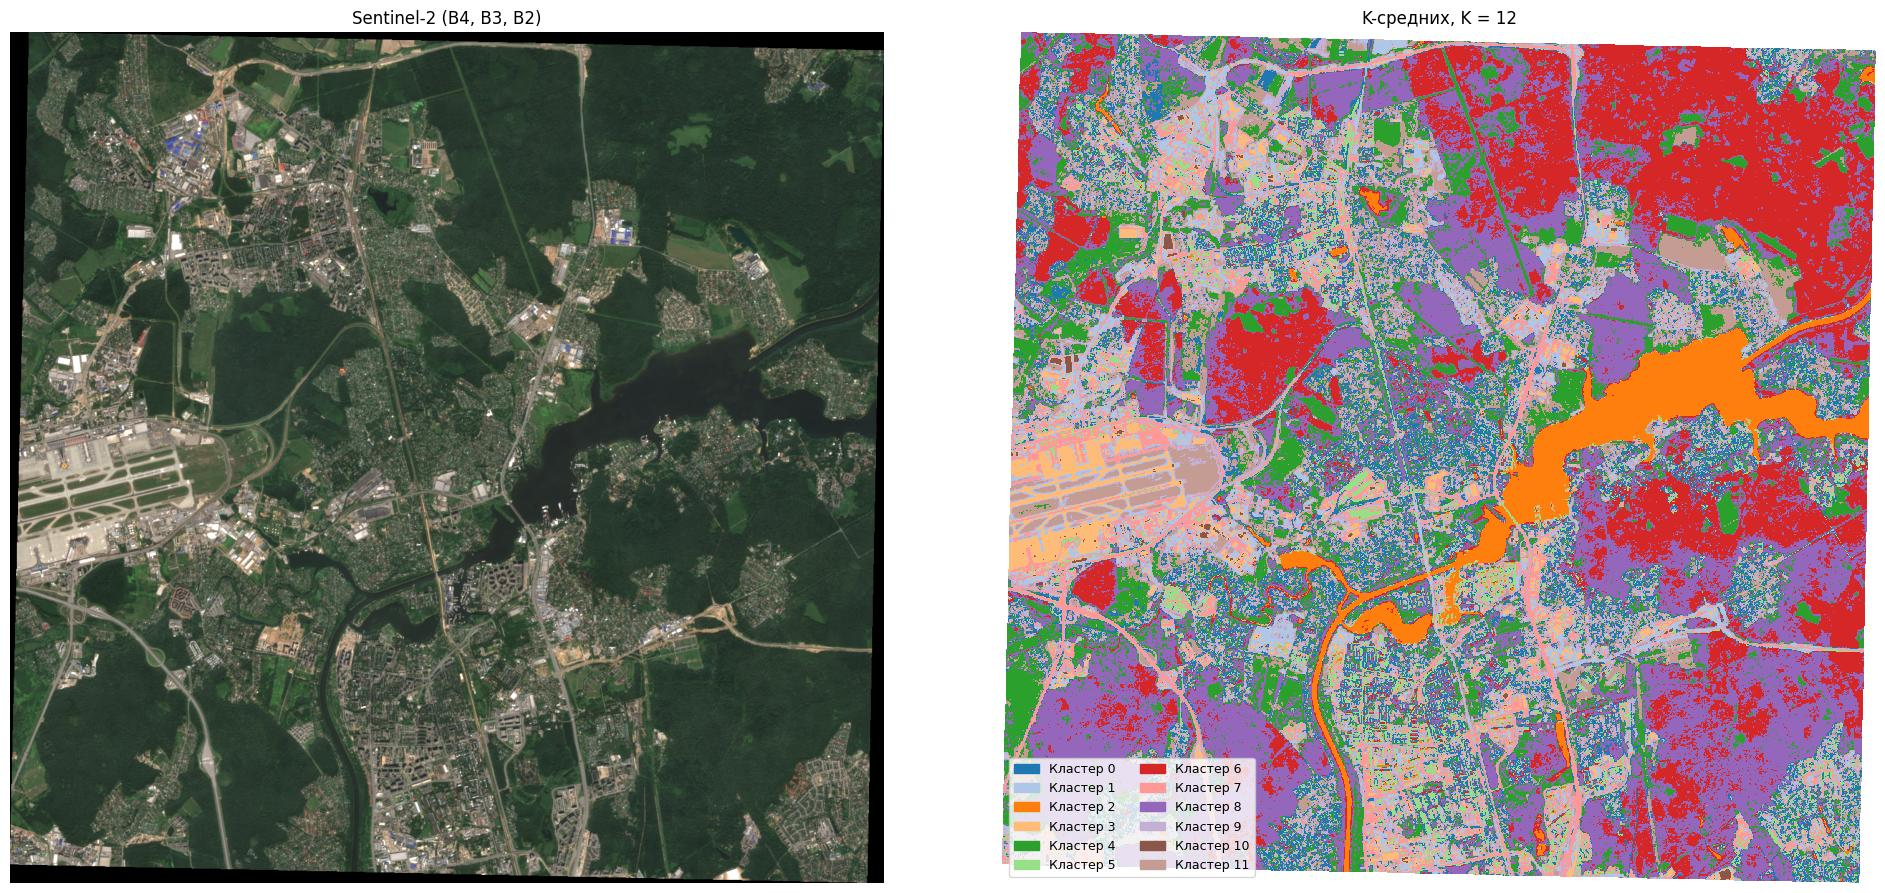

In [ ]:
cluster_colors = plt.cm.tab20(np.linspace(0, 1, 20))[:K]
cluster_cmap = ListedColormap(cluster_colors)

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
axes[0].imshow(rgb)
axes[0].set_title('Sentinel-2 (B4, B3, B2)')
axes[1].imshow(np.ma.masked_less(cluster_map, 0), cmap=cluster_cmap, vmin=-0.5, vmax=K - 0.5, interpolation='nearest')
axes[1].set_title(f'K-средних, K = {K}')
axes[1].legend(handles=[Patch(color=cluster_colors[k], label=f'Кластер {k}') for k in range(K)],
               loc='lower left', fontsize=9, ncol=2)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

Карта кластеров повторяет основные элементы снимка без всякой разметки: водохранилище и реки выделены одним кластером (2), лесные массивы — несколькими (6, 8, 4), аэродромные покрытия и открытый грунт — кластером 3. Застроенные территории окрашены пёстро: в них смешаны пиксели многих кластеров, так как городская среда неоднородна по спектру — крыши, асфальт, газоны и деревья в пределах одного квартала.

### **3.3. Спектральные профили кластеров**

Номер кластера сам по себе ничего не говорит. Чтобы понять, какие пиксели собраны в кластер, посмотрим на его **спектральный профиль** — средние значения отражения пикселей кластера в каждом канале. Профиль работает как «подпись» поверхности: у воды отражение низкое во всех каналах, у растительности резко растёт в ближнем ИК (B8), у искусственных покрытий и почвы высокое в коротковолновом ИК (B11, B12).

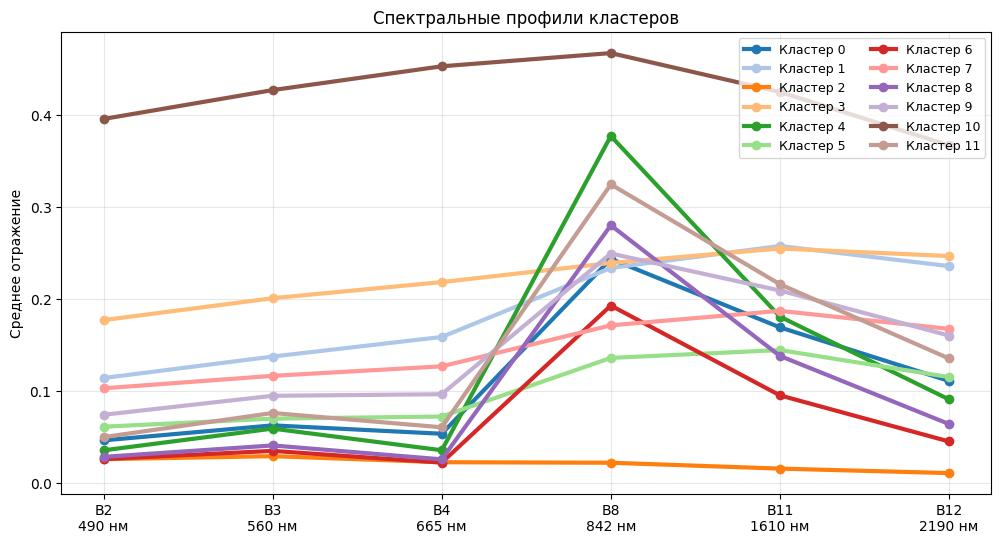

,B2,B3,B4,B8,B11,B12,NDVI,"Площадь, га"
0,0.046,0.063,0.053,0.244,0.169,0.111,0.637,1749.91
1,0.114,0.137,0.159,0.234,0.258,0.236,0.188,739.23
2,0.026,0.029,0.022,0.022,0.015,0.011,-0.053,769.76
3,0.177,0.201,0.218,0.239,0.255,0.247,0.041,460.13
4,0.035,0.059,0.035,0.377,0.181,0.091,0.827,2178.80
5,0.061,0.070,0.072,0.136,0.144,0.115,0.297,760.19
6,0.026,0.035,0.022,0.193,0.095,0.045,0.791,3172.11
7,0.103,0.116,0.127,0.171,0.187,0.167,0.146,1073.84
8,0.028,0.041,0.026,0.280,0.138,0.064,0.832,4306.77
9,0.074,0.095,0.096,0.249,0.209,0.160,0.440,1434.47


In [ ]:
WAVELENGTHS = [490, 560, 665, 842, 1610, 2190]   # центральные длины волн каналов, нм
labels_valid = cluster_map[valid]
profiles = pd.DataFrame([pixels[labels_valid == k].mean(axis=0) for k in range(K)], columns=BANDS)
profiles['NDVI'] = [ndvi[labels_valid == k].mean() for k in range(K)]
profiles['Площадь, га'] = areas.values

fig, ax = plt.subplots(figsize=(12, 6))
for k in range(K):
    ax.plot(range(len(BANDS)), profiles.loc[k, BANDS], 'o-', color=cluster_colors[k], linewidth=3, label=f'Кластер {k}')
ax.set_xticks(range(len(BANDS)), [f'{b}\n{w} нм' for b, w in zip(BANDS, WAVELENGTHS)])
ax.set_ylabel('Среднее отражение')
ax.set_title('Спектральные профили кластеров')
ax.grid(True, alpha=0.3)
ax.legend(ncol=2, fontsize=9)
plt.show()

profiles.round(3)

### **3.4. Как дать кластерам названия**

Второй способ понять кластеры — сравнить их с известной картой. Построим таблицу: какая доля пикселей каждого кластера относится к каждому классу Dynamic World. Важно: Dynamic World не участвовал в кластеризации, мы используем его только как подсказку для интерпретации.

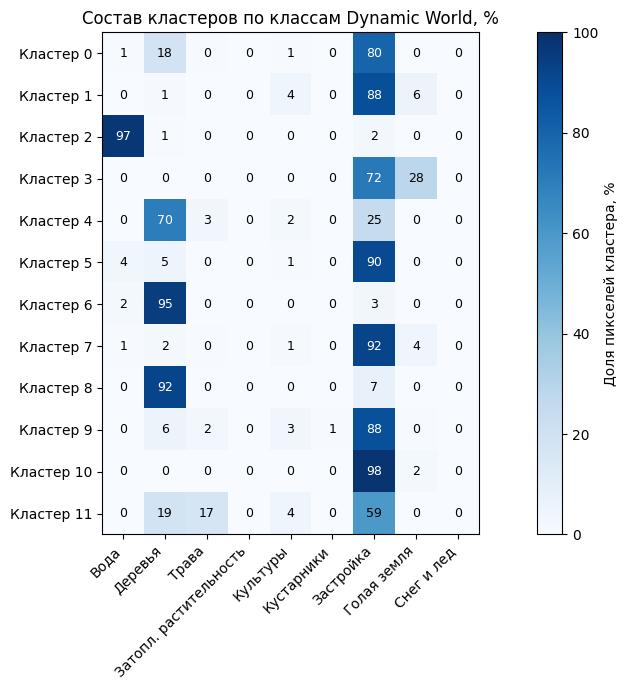

In [ ]:
dw_valid = dw[valid]
crosstab = pd.crosstab(labels_valid, dw_valid, normalize='index') * 100
crosstab.columns = [DW_NAMES[c] for c in crosstab.columns]
crosstab.index = [f'Кластер {k}' for k in crosstab.index]

fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(crosstab.values, cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(crosstab.shape[1]), crosstab.columns, rotation=45, ha='right')
ax.set_yticks(range(K), crosstab.index)
for i in range(K):
    for j in range(crosstab.shape[1]):
        ax.text(j, i, f'{crosstab.values[i, j]:.0f}', ha='center', va='center',
                color='white' if crosstab.values[i, j] > 60 else 'black', fontsize=9)
plt.colorbar(im, label='Доля пикселей кластера, %')
ax.set_title('Состав кластеров по классам Dynamic World, %')
plt.tight_layout()
plt.show()

Объединив спектральные профили, состав по Dynamic World и вид кластеров на снимке, можно дать кластерам названия. Названия — это интерпретация исследователя, а не результат алгоритма.

| Кластер | Площадь, га | Спектральный профиль | Состав по Dynamic World | Возможное название |
|---|---|---|---|---|
| 2 | 770 | Низкое отражение во всех каналах, NDVI < 0 | Вода 97% | Вода |
| 6 | 3172 | NDVI 0,79, умеренный ближний ИК (0,19), низкий SWIR | Деревья 95% | Тёмный лес (так выглядят хвойные массивы) |
| 8 | 4307 | NDVI 0,83, ближний ИК 0,28 | Деревья 92% | Лиственный и смешанный лес |
| 4 | 2179 | NDVI 0,83, самый высокий ближний ИК (0,38) | Деревья 70%, застройка 25% | Сочная растительность: молодой лес, кустарники, травы |
| 11 | 1679 | NDVI 0,69, высокий ближний ИК, выше SWIR | Застройка 59%, деревья 19%, трава 17% | Газоны и луга, в том числе поля аэродрома |
| 0 | 1750 | NDVI 0,64 | Застройка 80%, деревья 18% | Малоэтажная застройка с деревьями и садами |
| 9 | 1434 | NDVI 0,44 | Застройка 88% | Застройка с дворами и озеленением |
| 7 | 1074 | NDVI 0,15, средняя яркость во всех каналах | Застройка 92% | Крыши, дороги и асфальт средней яркости |
| 5 | 760 | Тёмный профиль, NDVI 0,30 | Застройка 90% | Тёмные крыши, асфальт и тени |
| 1 | 739 | NDVI 0,19, яркость растёт к SWIR | Застройка 88%, голая земля 6% | Светлые крыши и покрытия |
| 3 | 460 | Яркий плоский профиль (0,18–0,25), NDVI 0,04 | Застройка 72%, голая земля 28% | Бетон, песок, открытый грунт, стройплощадки |
| 10 | 40 | Очень яркий профиль (0,37–0,47) во всех каналах | Застройка 98% | ? — разберём в разделе 5 |

### **3.5. Кластеризация на серверах Google Earth Engine**

Для больших территорий выгружать снимок не обязательно: в GEE есть собственные алгоритмы кластеризации (`ee.Clusterer`). Процедура та же, что и в `scikit-learn`: обучить алгоритм на выборке пикселей (метод `sample`), а затем применить его ко всему изображению (метод `cluster`). Вычисления выполняются на серверах Google, а на карту выводится готовый результат.

**Метод ee.Clusterer.wekaKMeans():**
- `nClusters` — число кластеров
- `init` — способ инициализации: 0 — случайный, 1 — k-means++
- `seed` — начальное значение генератора случайных чисел

Здесь признаки не стандартизируются, так как используются только каналы отражения с близким разбросом значений.

In [ ]:
training = composite.sample(region=roi, scale=SCALE, numPixels=5000, seed=0)
clusterer = ee.Clusterer.wekaKMeans(nClusters=K, init=1, seed=0).train(training)
clustered = composite.cluster(clusterer)

map_clusters = geemap.Map()
map_clusters.add_basemap('Esri.WorldImagery')
map_clusters.centerObject(roi, 12)
map_clusters.addLayer(composite, {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 0.3, 'gamma': 1.4}, 'Sentinel-2')
map_clusters.addLayer(clustered.randomVisualizer(), {}, 'Кластеры (GEE)')
map_clusters

Map(center=[55.98001793820693, 37.51000000000046], controls=(WidgetControl(options=['position', 'transparent_b…

Номера и цвета кластеров GEE не совпадают с нашими: нумерация кластеров произвольна и зависит от инициализации. Совпадает смысл — похожие поверхности попадают в одни группы.

### **Выводы по разделу 3:**

1. **K-средних без разметки** разделил снимок на группы, которые хорошо соответствуют реальным поверхностям: вода выделена почти без примесей (97% пикселей кластера — вода по Dynamic World), лес — двумя кластерами с разным отражением в ближнем ИК
2. **Названия кластерам** даёт исследователь, опираясь на спектральные профили, сравнение с известной картой и визуальный просмотр
3. **Застроенная территория** неоднородна по спектру и распадается на несколько кластеров: крыши разной яркости, асфальт, дворы с озеленением
4. **В Google Earth Engine** та же кластеризация выполняется на серверах (`ee.Clusterer`), что позволяет обрабатывать большие территории без выгрузки снимков

---

## **Раздел 4. Кластеризация и классификация: сравнение**

### **4.1. Заданные классы и структура данных**

Классификация отвечает на вопрос, заданный заранее: «какой из девяти классов Dynamic World здесь?». Кластеризация показывает, на какие группы снимок делится сам по своим спектральным свойствам. Эти разбиения не обязаны совпадать, и именно расхождения между ними наиболее информативны.

### **4.2. Один класс — несколько кластеров, один кластер — несколько классов**

Посмотрим на обратную таблицу: на какие кластеры делится каждый класс Dynamic World.

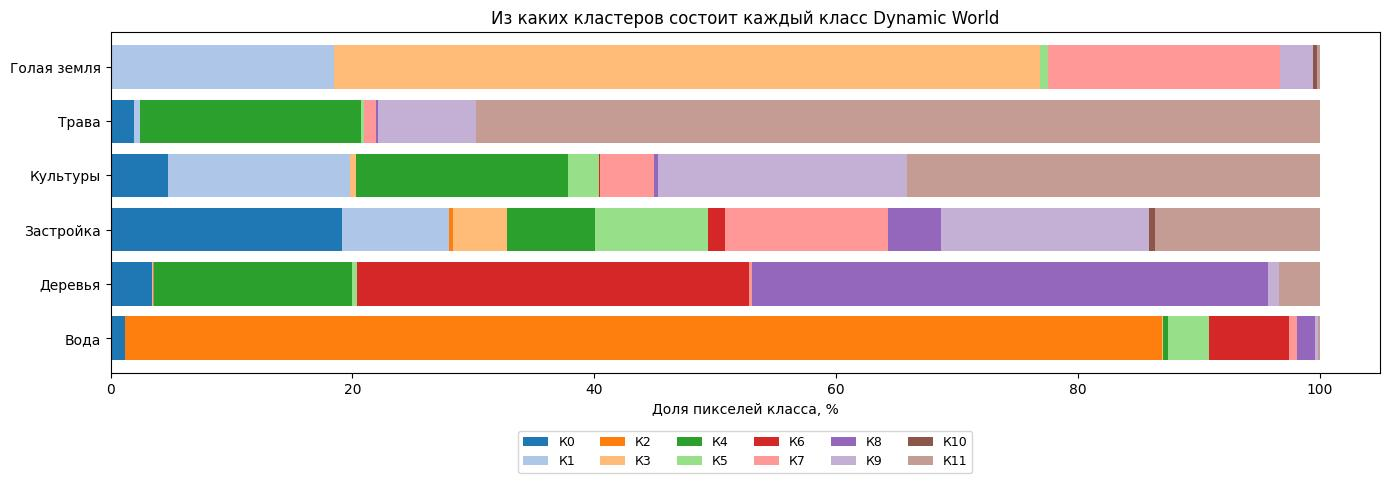

,К0,К1,К2,К3,К4,К5,К6,К7,К8,К9,К10,К11
Вода,1.1,0.0,85.8,0.1,0.5,3.4,6.6,0.7,1.5,0.2,0.0,0.1
Деревья,3.4,0.1,0.0,0.0,16.4,0.4,32.4,0.2,42.7,0.9,0.0,3.4
Застройка,19.1,8.9,0.3,4.5,7.3,9.3,1.4,13.5,4.4,17.2,0.5,13.6
Культуры,4.7,15.1,0.0,0.5,17.6,2.6,0.0,4.5,0.3,20.7,0.0,34.1
Трава,1.9,0.5,0.0,0.0,18.3,0.2,0.0,1.0,0.1,8.1,0.0,69.8
Голая земля,0.0,18.5,0.0,58.4,0.0,0.6,0.0,19.2,0.0,2.8,0.3,0.2


In [ ]:
inverse = pd.crosstab(dw_valid, labels_valid, normalize='index') * 100
inverse.index = [DW_NAMES[c] for c in inverse.index]
inverse.columns = [f'К{k}' for k in inverse.columns]
main = inverse.loc[[name for name in ['Вода', 'Деревья', 'Застройка', 'Культуры', 'Трава', 'Голая земля'] if name in inverse.index]]

ax = main.plot(kind='barh', stacked=True, figsize=(14, 5), color=cluster_colors, width=0.8)
ax.set_xlabel('Доля пикселей класса, %')
ax.set_title('Из каких кластеров состоит каждый класс Dynamic World')
ax.legend(ncol=6, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.tight_layout()
plt.show()

main.round(1)

Класс «Застройка» Dynamic World оказывается самым неоднородным: его пиксели распределены по многим кластерам — 0 (19%), 9 (17%), 11 (14%), 7 (14%), 5 (9%), 1 (9%) и другим. Для классификатора всё это один класс, а по спектру это разные поверхности: малоэтажная застройка с садами, асфальт, тёмные и светлые крыши, газоны. «Деревья» делятся на три кластера (8 — 43%, 6 — 32%, 4 — 16%), «Голая земля» в основном попадает в кластер 3 (58%). Только вода почти целиком собрана в одном кластере (86% в кластере 2).

Обратная ситуация тоже встречается: кластер 0 на 80% состоит из застройки и на 18% из деревьев, кластер 4 — на 70% из деревьев и на 25% из застройки. Это пиксели переходных участков, где на 10 метрах смешиваются крыши и кроны деревьев.

### **4.3. Когда что применять**

| | **Классификация** | **Кластеризация** |
|---|---|---|
| Есть размеченные данные или готовая эталонная карта | Подходит | Не обязательна |
| Нужны заранее заданные категории (для отчёта, статистики, сравнения с нормативами) | Подходит | Названия придётся присваивать вручную |
| Разметки нет, территория неизвестна | Невозможна без разметки | Подходит: первый обзор данных |
| Нужно найти необычные, заранее неизвестные объекты | Не найдёт: знает только свои классы | Подходит |
| Подготовка разметки для классификации | — | Подходит: кластеры подсказывают, какие классы выделять и где брать примеры |

На практике методы дополняют друг друга: кластеризация помогает исследовать данные и выбрать классы, классификация — получить устойчивую карту заданных категорий.

### **Выводы по разделу 4:**

1. **Классификация и кластеризация** дают разные разбиения одного снимка: первая — по заданной легенде, вторая — по спектральному сходству
2. **Один класс** легенды может соответствовать нескольким спектрально разным группам (застройка в Dynamic World — семи и более кластерам), а **один кластер** — включать пиксели нескольких классов (переходные участки)
3. **Методы дополняют друг друга**: кластеризация полезна для разведки данных и выбора классов, классификация — для получения карты заданных категорий

---

## **Раздел 5. «Иголка в стоге сена»: поиск неожиданных классов**

Готовые карты классификации содержат только те классы, которые заложили их авторы. Если на территории есть объекты особого типа, которых нет в легенде, классификатор отнесёт их к одному из имеющихся классов, и они «растворятся» в нём. Кластеризация не ограничена легендой: если группа пикселей заметно отличается от остальных по спектру, она может выделиться в собственный кластер, даже если занимает доли процента площади.

### **5.1. Малые кластеры**

Найдём самый маленький кластер и посмотрим, где он расположен.

Самый маленький кластер: 10, площадь 40.2 га (0.22% площади снимка)
Состав по Dynamic World: Застройка 98%, Голая земля 2%
Средний профиль: {'B2': 0.396, 'B3': 0.427, 'B4': 0.453, 'B8': 0.467, 'B11': 0.425, 'B12': 0.367}


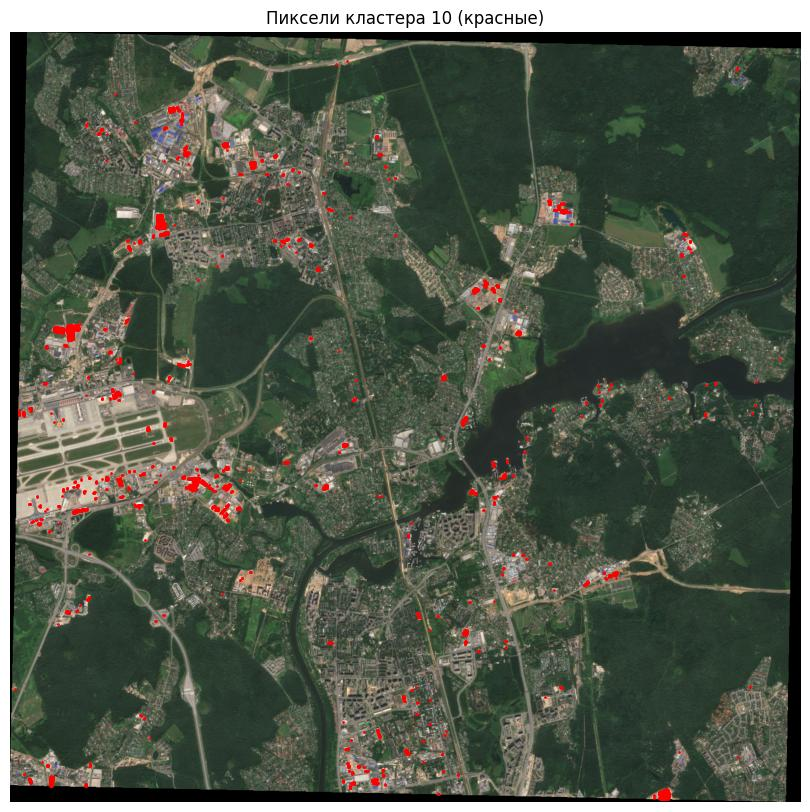

In [ ]:
rare = int(areas.idxmin())
print(f'Самый маленький кластер: {rare}, площадь {areas[rare]:.1f} га ({areas[rare] / areas.sum():.2%} площади снимка)')
print(f'Состав по Dynamic World: ' + ', '.join(f'{name} {share:.0f}%' for name, share in crosstab.loc[f'Кластер {rare}'].sort_values(ascending=False).head(2).items()))
print('Средний профиль:', profiles.loc[rare, BANDS].round(3).to_dict())

rows, cols = np.nonzero(cluster_map == rare)
plt.figure(figsize=(11, 10))
plt.imshow(rgb)
plt.scatter(cols, rows, s=1, color='red')
plt.title(f'Пиксели кластера {rare} (красные)')
plt.axis('off')
plt.show()

Рассмотрим несколько участков крупным планом: слева — снимок, справа — тот же участок с пикселями кластера.

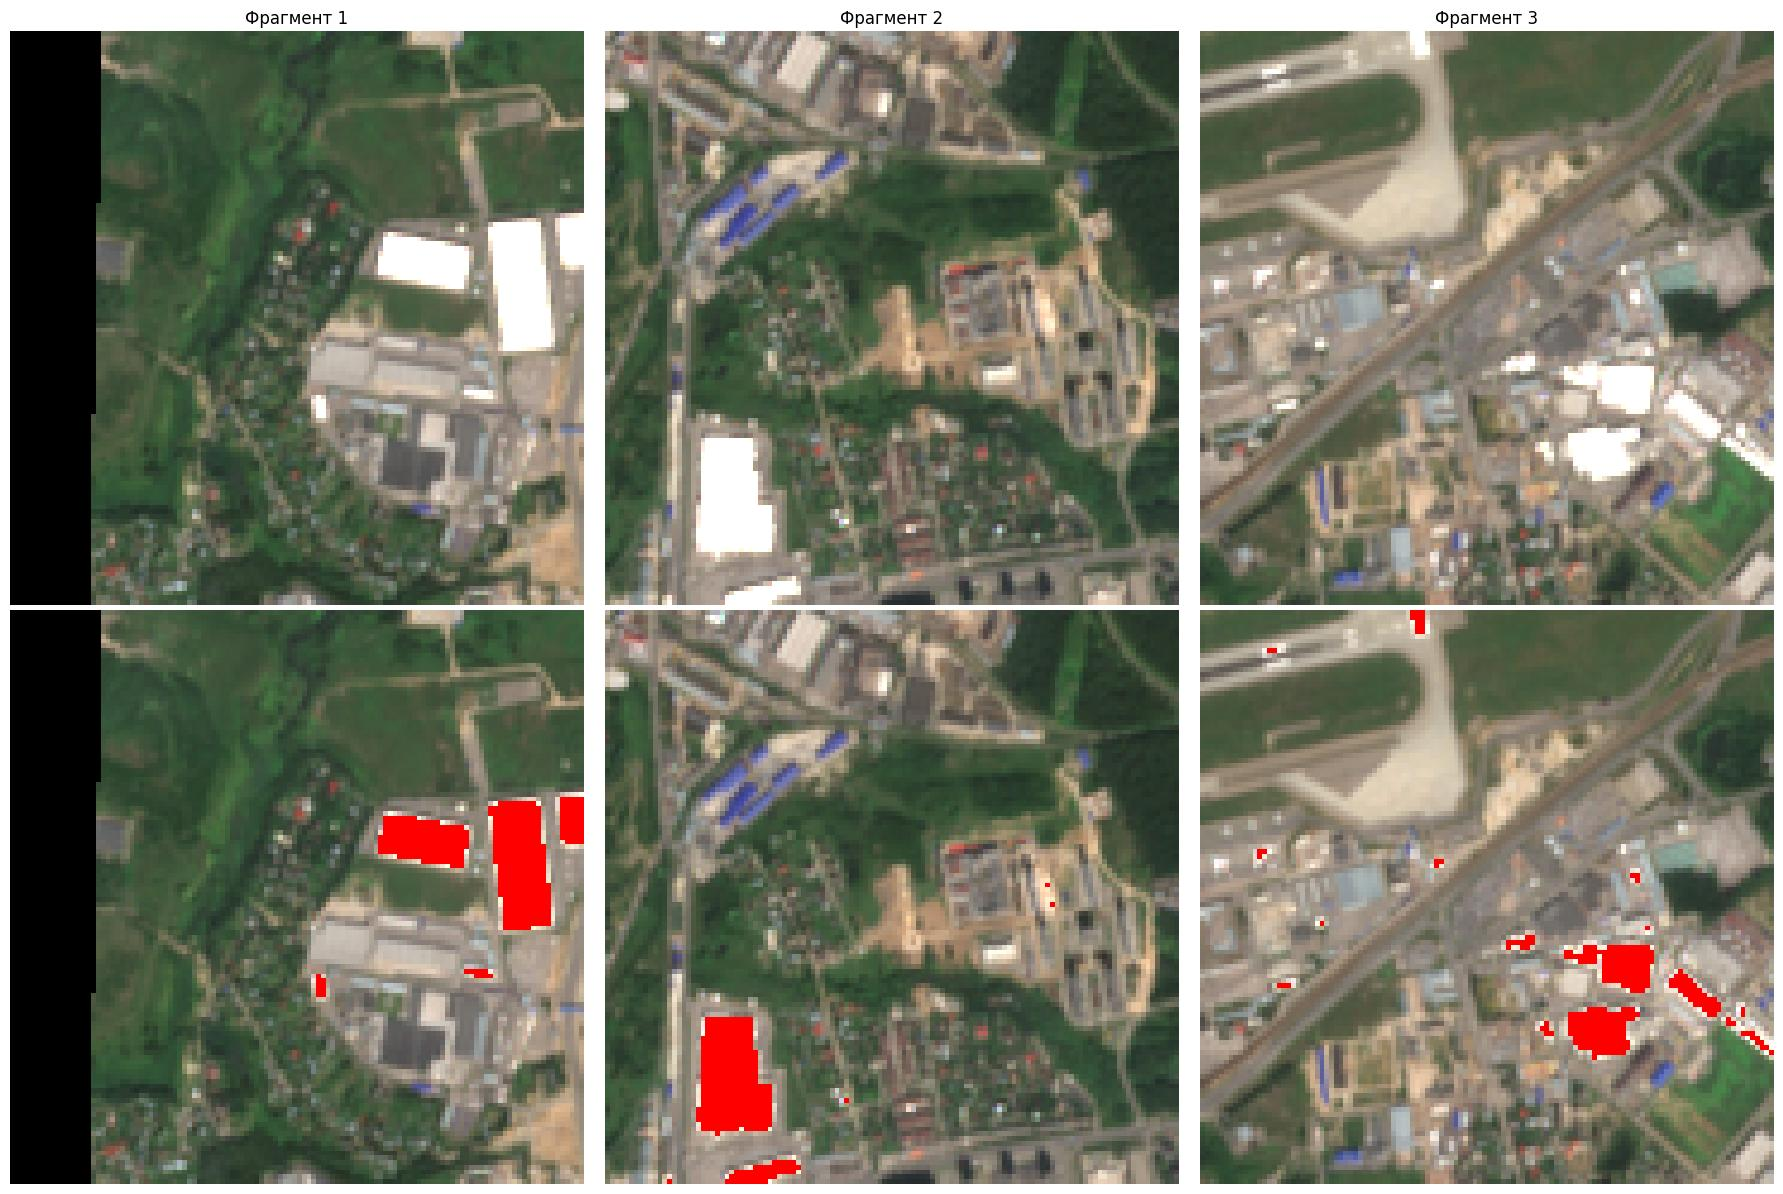

In [ ]:
def zoom_views(mask, centers, size=60, color=(1, 0, 0)):
    """Фрагменты снимка вокруг заданных точек: исходный и с подсветкой пикселей маски."""
    fig, axes = plt.subplots(2, len(centers), figsize=(6 * len(centers), 12))
    for j, (r, c) in enumerate(centers):
        r, c = min(max(r, size), H - size), min(max(c, size), W - size)   # окно целиком внутри снимка
        r0, c0 = r - size, c - size
        crop = rgb[r0:r + size, c0:c + size]
        highlight = crop.copy()
        highlight[mask[r0:r + size, c0:c + size]] = color
        axes[0, j].imshow(crop)
        axes[1, j].imshow(highlight)
        axes[0, j].set_title(f'Фрагмент {j + 1}')
        for ax in axes[:, j]:
            ax.axis('off')
    plt.tight_layout()
    plt.show()

# Центры фрагментов — участки с наибольшим числом пикселей кластера в окне 120×120 пикселей
mask_rare = cluster_map == rare
density = np.add.reduceat(np.add.reduceat(mask_rare.astype(int), np.arange(0, H, 120), axis=0), np.arange(0, W, 120), axis=1)
best = np.dstack(np.unravel_index(np.argsort(density.ravel())[::-1][:3], density.shape))[0]
zoom_views(mask_rare, [(r * 120 + 60, c * 120 + 60) for r, c in best])

Самый маленький кластер (10) занимает около 40 га — 0,22% площади снимка. Его спектральный профиль — очень высокое и почти одинаковое отражение во всех каналах (0,37–0,47), что соответствует белым поверхностям. На фрагментах видно, что это **белые крыши крупных складов, логистических комплексов и терминалов**, в основном в промышленных зонах и у аэропорта Шереметьево.

В Dynamic World эти пиксели на 98% относятся к классу «Застройка» — вместе с жилыми домами, дорогами и дворами. Класса «крупные складские и промышленные здания» в легенде нет, поэтому классификатор их и не может выделить. Кластеризация нашла эту группу, хотя ей никто не сообщал о её существовании: спектр белых крыш настолько отличается от всего остального снимка, что алгоритм выделил для них отдельный центроид. Это и есть «иголка в стоге сена» — объекты, которых мы не закладывали в классы, но которые могут быть важны, например, для учёта складской недвижимости или оценки нагрева городских поверхностей.

### **5.2. Как рост числа кластеров открывает новые группы**

При малом $K$ алгоритм выделяет только крупные группы: малочисленные пиксели «приклеиваются» к ближайшему большому кластеру. С ростом $K$ появляется возможность выделить и небольшие, но отличающиеся группы. Сравним размеры самых маленьких кластеров при разных $K$.

In [ ]:
rows = []
for k in [4, 8, 12, 16]:
    km = KMeans(n_clusters=k, n_init=5, random_state=0).fit(features_scaled[sample])
    lab = km.predict(features_scaled)
    sizes = np.bincount(lab, minlength=k) * PIXEL_AREA_HA
    smallest = sizes.argmin()
    brightness = pixels[lab == smallest].mean()
    rows.append({'K': k, 'Самый малый кластер, га': round(sizes[smallest], 1),
                 'Доля площади, %': round(100 * sizes[smallest] / sizes.sum(), 2),
                 'Среднее отражение по каналам': round(float(brightness), 3)})
pd.DataFrame(rows)

,K,"Самый малый кластер, га","Доля площади, %",Среднее отражение по каналам
0,4,939.5,5.12,0.030
1,8,45.7,0.25,0.408
2,12,40.2,0.22,0.423
3,16,18.8,0.10,0.506


При $K = 4$ самый маленький кластер — вода (около 940 га, 5% площади), а белые крыши ещё «растворены» в кластерах застройки. Начиная с $K = 8$ белые крыши выделяются в собственный кластер (46 га, среднее отражение 0,41), при $K = 12$ это наш кластер 10 (40 га), а при $K = 16$ в отдельный кластер уходят только самые яркие из них (19 га, отражение 0,51). Чем больше кластеров, тем меньшие и тем более специфические группы может выделить алгоритм.

### **5.3. Поиск редких объектов по расстоянию до центроида**

Кластер выделяется, только если похожих пикселей достаточно много. Единичные необычные объекты не образуют собственного кластера, но их тоже можно найти: такие пиксели находятся **далеко от всех центроидов**, потому что ни одна группа их хорошо не описывает. Расстояние от пикселя до ближайшего центроида — это мера его «необычности».

Самыми далёкими от центроидов окажутся в первую очередь пиксели уже найденного кластера белых крыш: они ярче всего остального снимка, и даже собственный центроид описывает их хуже, чем центроиды больших кластеров описывают свои пиксели. Поэтому необычное будем искать среди остальных пикселей, исключив уже найденный кластер.

Пикселей самого маленького кластера среди 0,1% самых далёких от центроидов: 72%
Порог: 4.25, необычных пикселей вне кластера 10: 1833 (18.3 га)


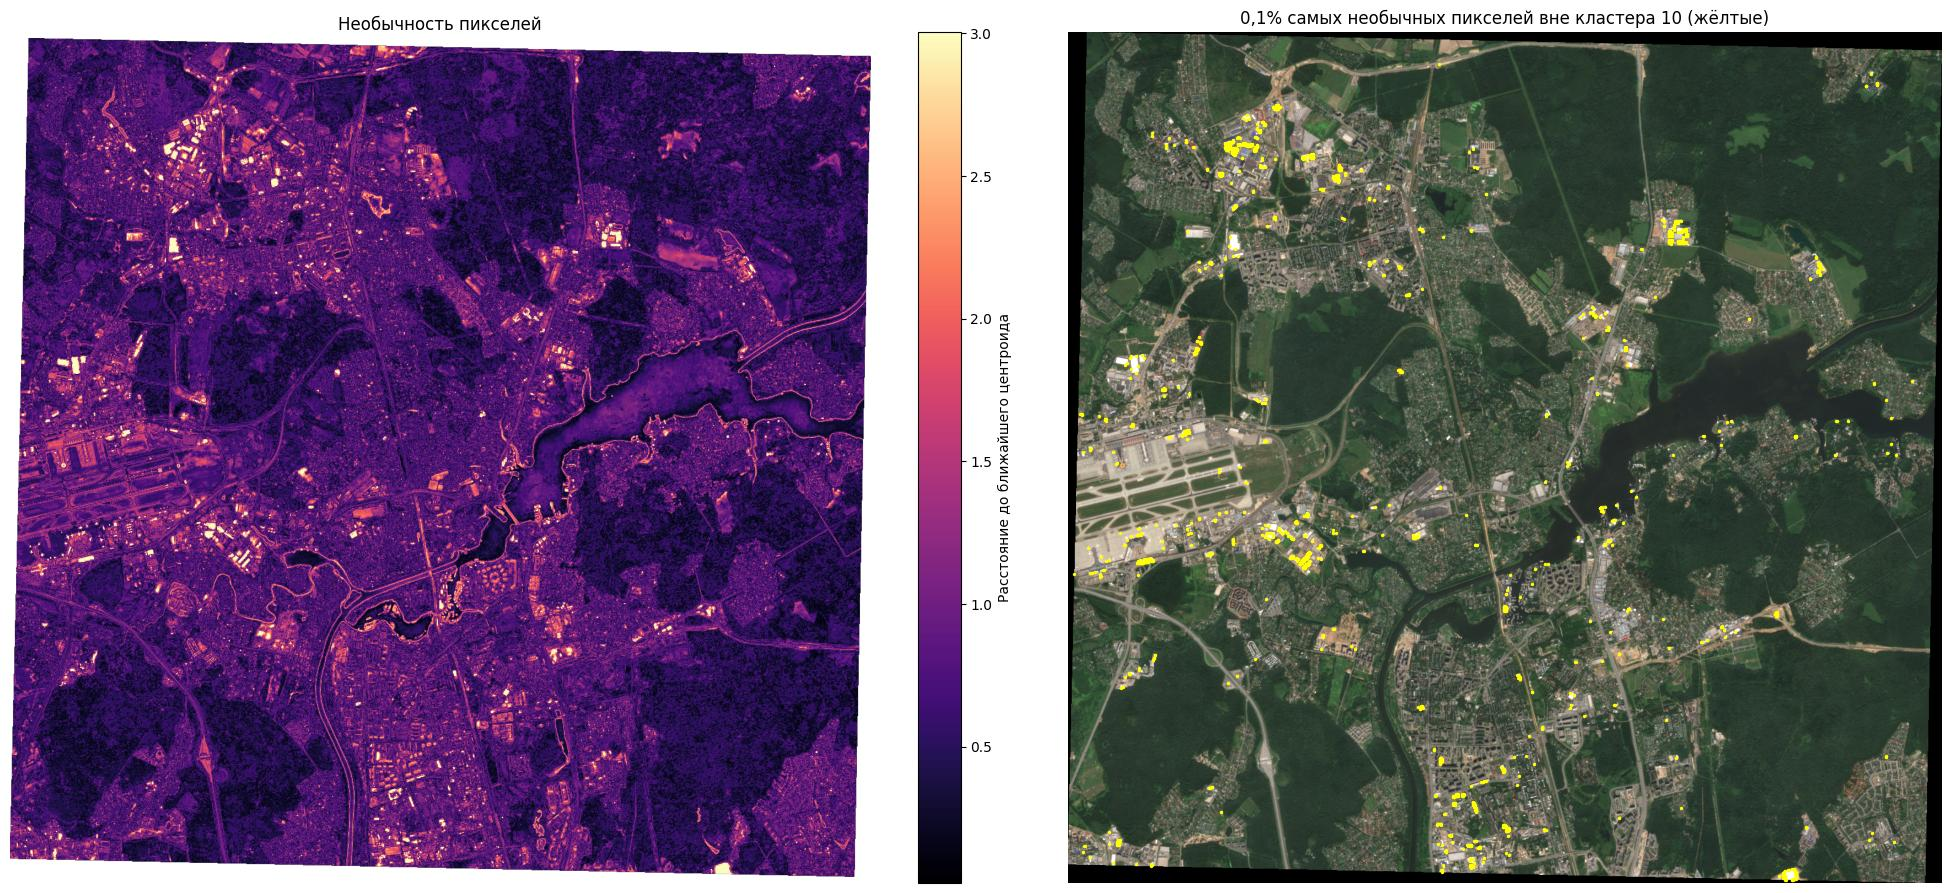

In [ ]:
distance_map = np.full((H, W), np.nan)
distance_map[valid] = kmeans.transform(features_scaled).min(axis=1)   # расстояние до ближайшего центроида

print(f'Пикселей самого маленького кластера среди 0,1% самых далёких от центроидов: '
      f'{np.mean(cluster_map[distance_map > np.nanpercentile(distance_map, 99.9)] == rare):.0%}')

# Ищем необычное среди остальных пикселей: уже найденный кластер исключаем
candidates = np.where(cluster_map == rare, np.nan, distance_map)
threshold = np.nanpercentile(candidates, 99.9)                            # 0,1% самых необычных пикселей
unusual = candidates > threshold
print(f'Порог: {threshold:.2f}, необычных пикселей вне кластера {rare}: {unusual.sum()} ({unusual.sum() * PIXEL_AREA_HA:.1f} га)')

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
im = axes[0].imshow(distance_map, cmap='magma', vmax=np.nanpercentile(distance_map, 99.5))
plt.colorbar(im, ax=axes[0], fraction=0.046, label='Расстояние до ближайшего центроида')
axes[0].set_title('Необычность пикселей')
axes[1].imshow(rgb)
rows_u, cols_u = np.nonzero(unusual)
axes[1].scatter(cols_u, rows_u, s=2, color='yellow')
axes[1].set_title(f'0,1% самых необычных пикселей вне кластера {rare} (жёлтые)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

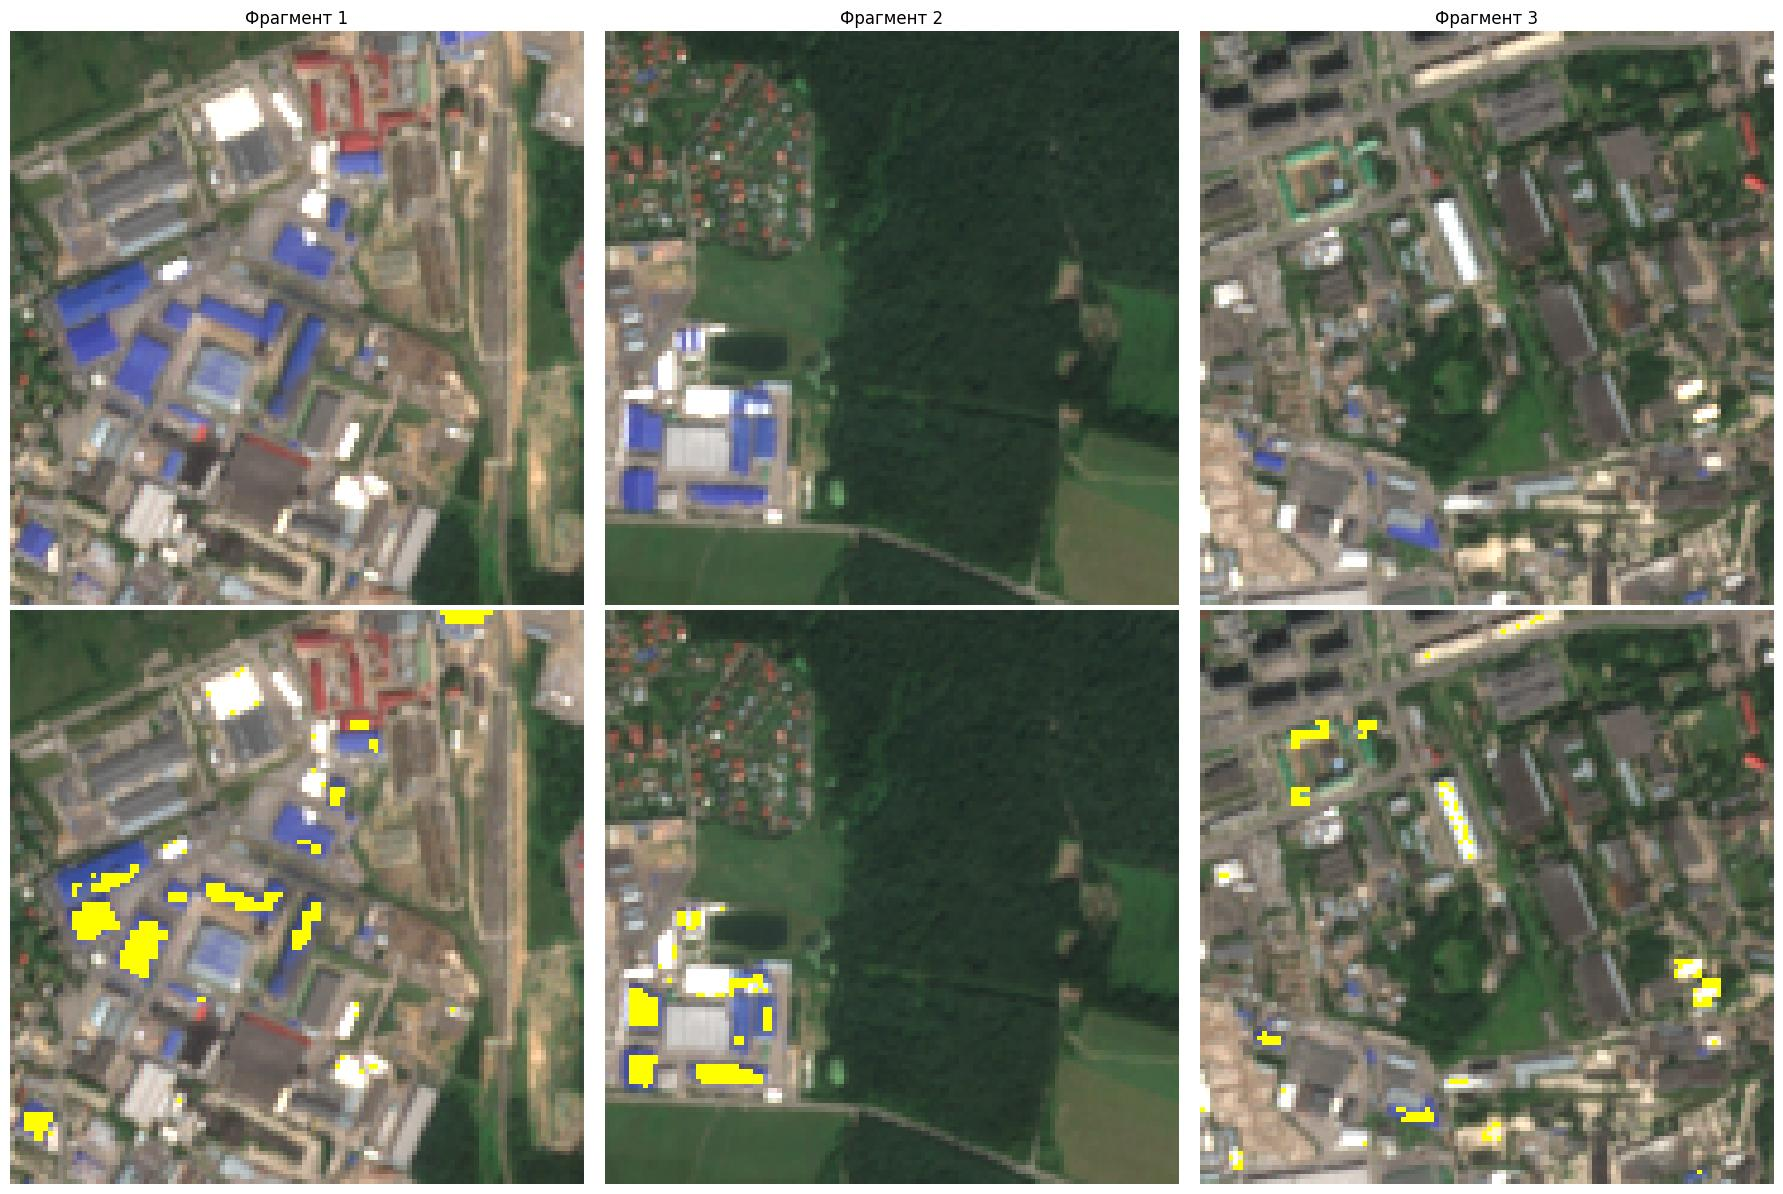

In [ ]:
density_u = np.add.reduceat(np.add.reduceat(unusual.astype(int), np.arange(0, H, 120), axis=0), np.arange(0, W, 120), axis=1)
best_u = np.dstack(np.unravel_index(np.argsort(density_u.ravel())[::-1][:3], density_u.shape))[0]
zoom_views(unusual, [(r * 120 + 60, c * 120 + 60) for r, c in best_u], color=(1, 1, 0))

72% из 0,1% самых далёких от центроидов пикселей — это белые крыши кластера 10. Исключив их, получаем около 18 га других необычных пикселей. На фрагментах видно, что это в первую очередь **синие крыши складских и торговых зданий** (фрагменты 1 и 2), а также бирюзово-зелёные крыши и отдельные светлые вытянутые постройки (фрагмент 3). Синих крыш на снимке слишком мало, чтобы при $K = 12$ они образовали собственный кластер, но их спектр (относительно высокое отражение в синем канале при низком в красном) не похож ни на один центроид — поэтому они и выделяются по расстоянию.

### **Выводы по разделу 5:**

1. **Готовые карты классификации** не могут показать объекты, которых нет в их легенде: такие объекты растворяются в ближайшем классе (белые крыши складов — в «Застройке»)
2. **Малые кластеры** выделяют спектрально необычные группы объектов: при $K = 12$ это 40 га белых крыш крупных складов и терминалов, 0,22% площади снимка
3. **Число кластеров** определяет, насколько мелкие группы можно увидеть: белые крыши выделяются в собственный кластер только начиная с $K = 8$
4. **Расстояние до ближайшего центроида** позволяет найти и единичные необычные объекты, которые не образуют своего кластера, — например, синие крыши складов

---

## **Раздел 6. Дополнительное применение: сжатие изображений**

### **6.1. Цветовая квантизация**

Цветное изображение хранит для каждого пикселя три числа — интенсивности красного (R), зелёного (G) и синего (B) каналов от 0 до 255, то есть 3 байта на пиксель. Всего возможно $256^3 \approx 16{,}7$ млн цветов, но в реальной фотографии большая часть из них не используется, а многие используемые почти неотличимы друг от друга.

**Цветовая квантизация** заменяет все цвета изображения небольшим набором из $K$ цветов — **палитрой**. K-средних подходит для этого естественным образом: каждый пиксель — точка в трёхмерном пространстве RGB, кластеры — группы похожих цветов, а центроид кластера — средний цвет группы, который и становится цветом палитры. Каждый пиксель заменяется цветом центроида своего кластера.

**Шаги сжатия:**
1. Изображение размером $H \times W \times 3$ преобразуется в массив $(H \cdot W) \times 3$ — по строке на пиксель
2. K-средних находит $K$ центроидов — цвета палитры (обучение на подвыборке пикселей ускоряет расчёт без заметной потери качества)
3. Каждому пикселю присваивается номер ближайшего центроида — индекс цвета в палитре
4. Изображение сохраняется как **палитра + индексы**

#### **Почему важно правильно сохранить результат**

Если просто заменить цвета пикселей на цвета центроидов и сохранить результат как обычное RGB-изображение, файл почти не уменьшится, а в формате JPEG может даже вырасти: каждый пиксель по-прежнему записывается тремя байтами, а JPEG вдобавок вносит новые оттенки на резких границах между цветами палитры.

Выигрыш даёт **палитровый (индексированный) формат PNG**: в файл записывается таблица из $K$ цветов и для каждого пикселя только номер цвета. Для номера достаточно $\lceil \log_2 K \rceil$ бит: 1 бит при 2 цветах, 2 бита при 4, 4 бита при 16, 8 бит (1 байт) при 256 цветах — вместо 24 бит на пиксель в RGB. PIL при сохранении с `optimize=True` сам выбирает наименьшую битность для числа цветов палитры, а сжатие без потерь внутри PNG дополнительно уменьшает файл, так как в изображении из нескольких цветов много повторяющихся последовательностей.

In [ ]:
def quantize(image, k, sample_size=50000, seed=0):
    """Квантизация RGB-изображения до k цветов методом K-средних: палитра и индексы."""
    h, w, _ = image.shape
    colors = image.reshape(-1, 3).astype('float32')
    sample = np.random.default_rng(seed).choice(len(colors), min(sample_size, len(colors)), replace=False)
    km = KMeans(n_clusters=k, n_init=1, random_state=seed).fit(colors[sample])
    palette = np.round(km.cluster_centers_).clip(0, 255).astype('uint8')
    indices = km.predict(colors).astype('uint8').reshape(h, w)
    return palette, indices

def to_palette_image(palette, indices):
    """Палитровое изображение PIL: индексы пикселей и таблица цветов."""
    img = Image.frombytes('P', (indices.shape[1], indices.shape[0]), indices.tobytes())
    img.putpalette(palette.flatten().tolist())
    return img

def file_size_kb(img, **save_args):
    """Размер файла (КБ) при сохранении изображения PIL с заданными параметрами."""
    buffer = io.BytesIO()
    img.save(buffer, **save_args)
    return len(buffer.getvalue()) / 1024

### **6.2. Сжатие фотографий и фрагмента снимка**

Возьмём три фотографии с разной детализацией и палитрой — песца на камнях, натюрморт с фруктами и мандрила с мелкой текстурой шерсти, — а также фрагмент спутникового снимка в естественных цветах.

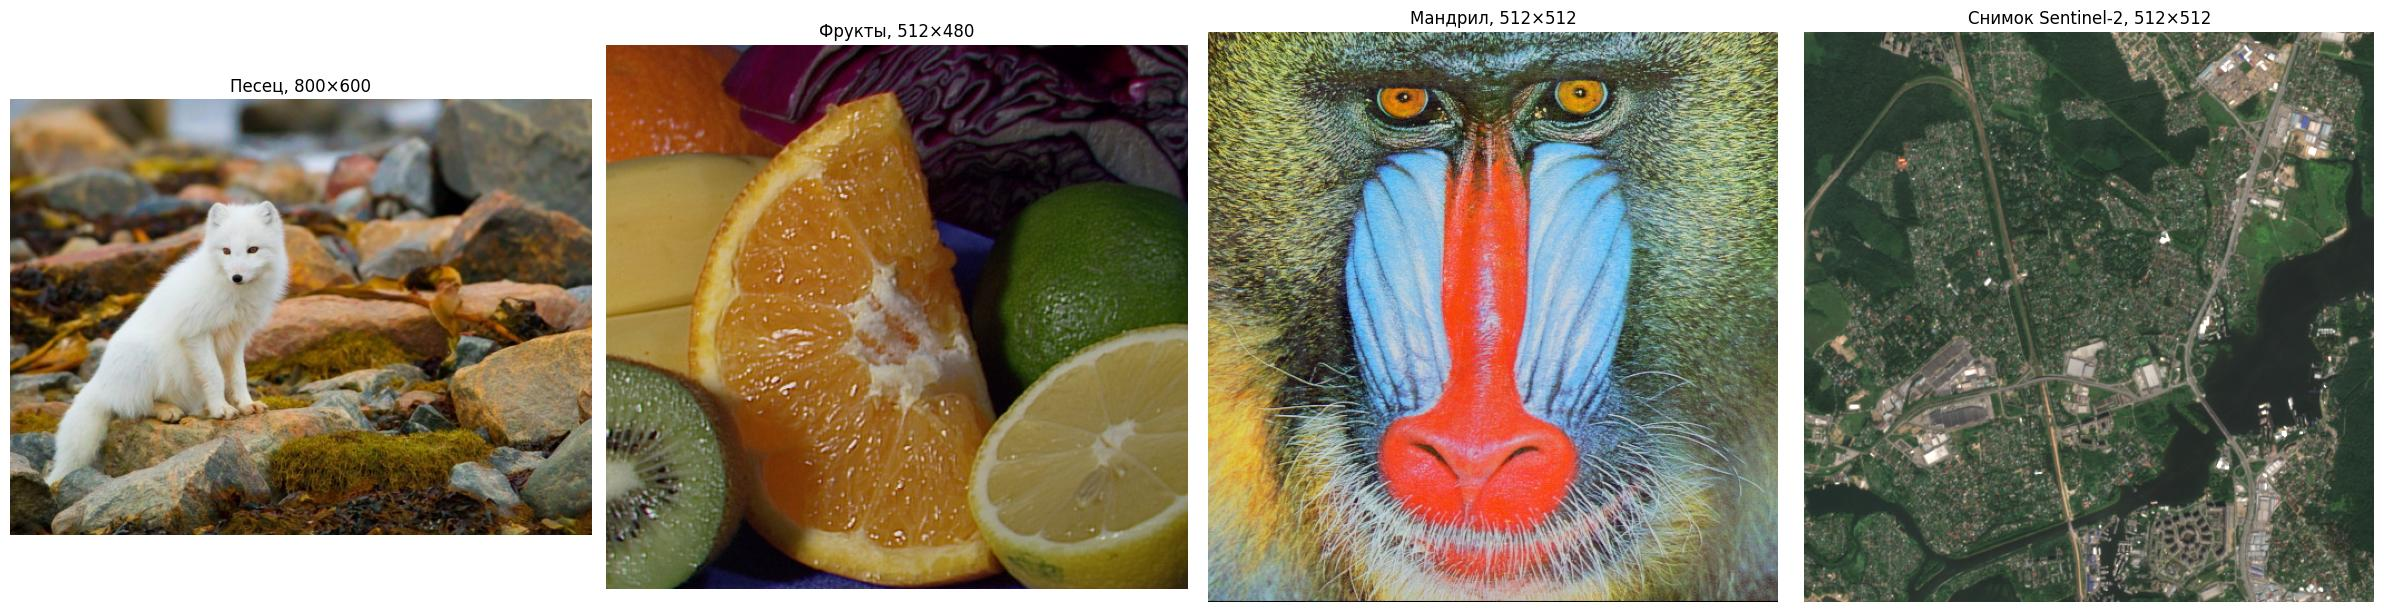

In [ ]:
PHOTOS = {
    'Песец': 'https://2spalnika.ru/wp-content/uploads/2022/12/zhivotniy-mir-hibin-800x600.jpg',
    'Фрукты': 'https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/fruits.jpg',
    'Мандрил': 'https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/baboon.jpg',
}
images, source_sizes = {}, {}
for name, url in PHOTOS.items():
    path = os.path.join('data', os.path.basename(url))
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    images[name] = np.array(Image.open(path).convert('RGB'))
    source_sizes[name] = os.path.getsize(path) / 1024

# Фрагмент спутникового снимка 512×512 пикселей в естественных цветах, 8 бит на канал
r0, c0 = (H - 512) // 2, (W - 512) // 2
images['Снимок Sentinel-2'] = (rgb[r0:r0 + 512, c0:c0 + 512] * 255).astype('uint8')

fig, axes = plt.subplots(1, 4, figsize=(24, 6))
for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img)
    ax.set_title(f'{name}, {img.shape[1]}×{img.shape[0]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

Сожмём каждое изображение до 4, 16 и 64 цветов и посмотрим на результат.

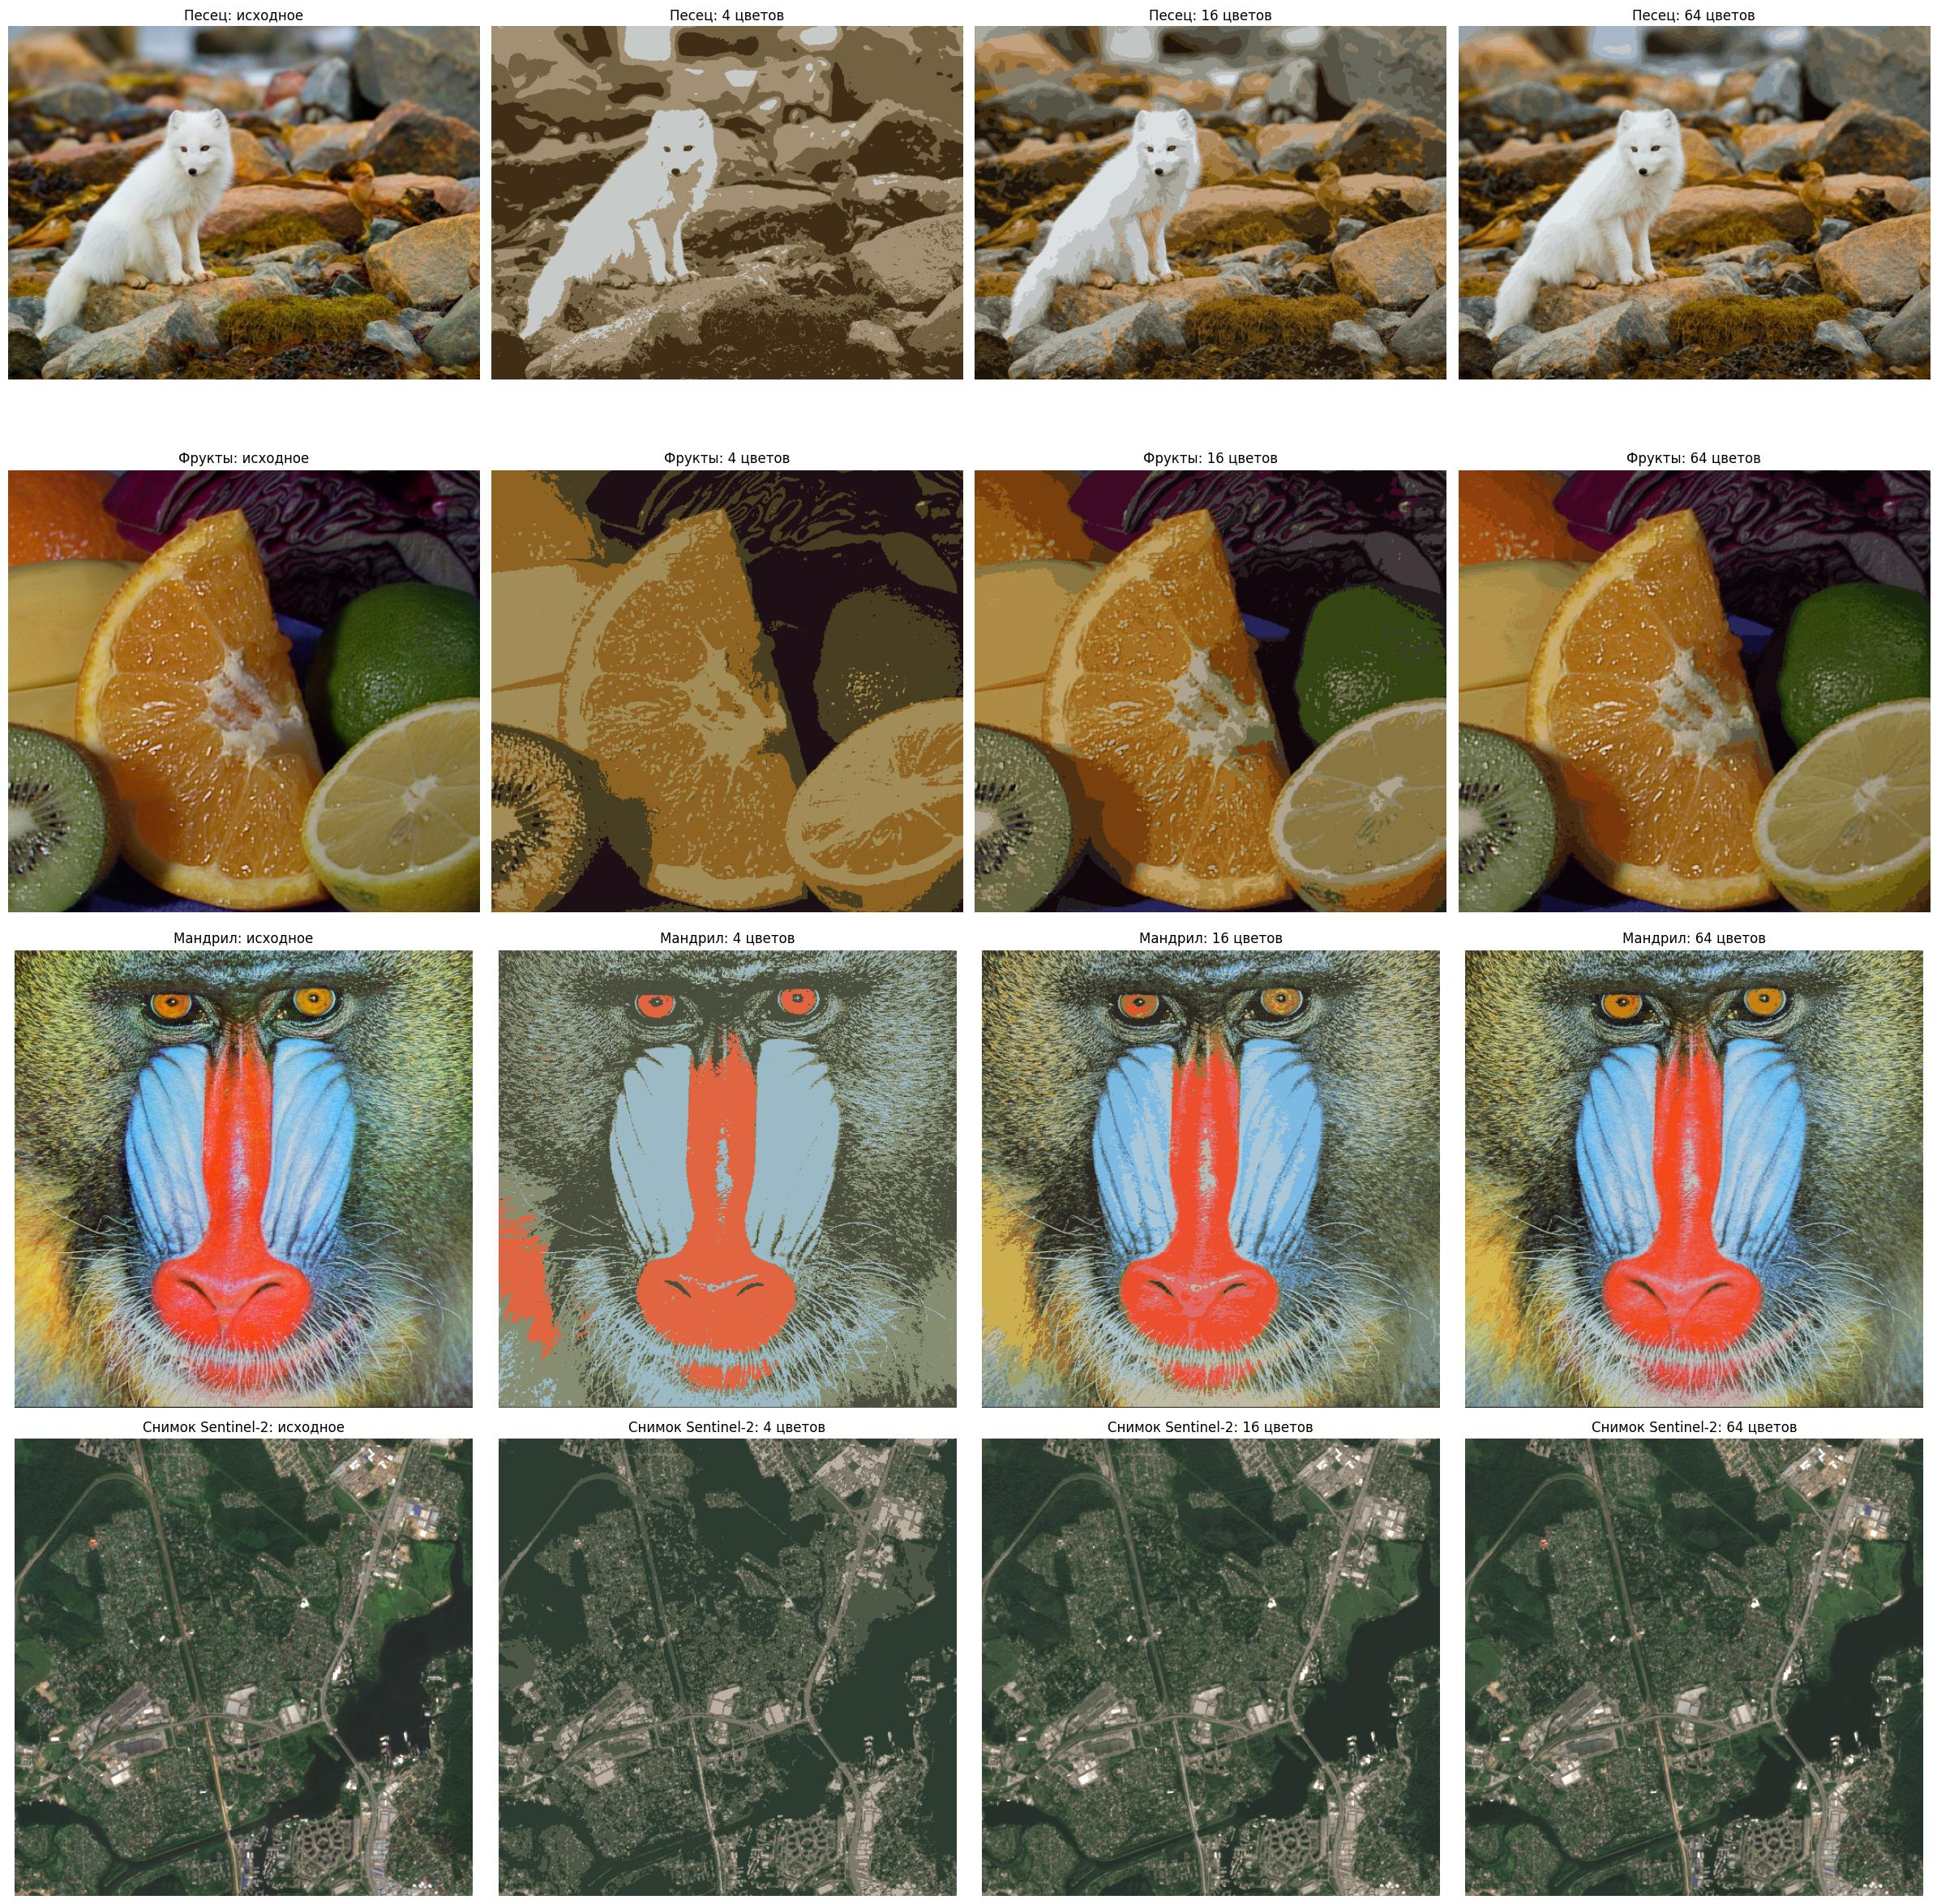

In [ ]:
K_SHOW = [4, 16, 64]
quantized = {name: {k: quantize(img, k) for k in K_SHOW} for name, img in images.items()}

fig, axes = plt.subplots(len(images), len(K_SHOW) + 1, figsize=(24, 6 * len(images)))
for i, (name, img) in enumerate(images.items()):
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f'{name}: исходное')
    for j, k in enumerate(K_SHOW, start=1):
        palette, indices = quantized[name][k]
        axes[i, j].imshow(palette[indices])
        axes[i, j].set_title(f'{name}: {k} цветов')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

При 4 цветах изображения превращаются в «плакат»: остаются только крупные пятна, мелкие оттенки и плавные переходы исчезают, хотя основные объекты узнаются. При 16 цветах изображения вполне узнаваемы, но на плавных переходах (фон за песцом, шерсть мандрила) видны ступеньки. При 64 цветах сжатые изображения в таком масштабе почти не отличаются от исходных. Фрагмент спутникового снимка уже при 16 цветах выглядит близко к исходному: в нём мало разных оттенков — в основном зелёные и серые.

Теперь сравним размеры файлов при разных способах сохранения. Для честного сравнения ориентиром служит размер изображения без сжатия (3 байта на пиксель) и его сохранение в PNG без потерь. Исходные фотографии загружены в формате JPEG, который уже сжимает изображение с потерями, поэтому их размер приведён отдельно.

In [ ]:
rows = []
for name, img in images.items():
    h_img, w_img, _ = img.shape
    original = Image.fromarray(img)
    for k in K_SHOW:
        palette, indices = quantized[name][k]
        restored = Image.fromarray(palette[indices])
        rows.append({
            'Изображение': name, 'Цветов': k,
            'Без сжатия, КБ': h_img * w_img * 3 / 1024,
            'PNG без потерь, КБ': file_size_kb(original, format='PNG', optimize=True),
            'Исходный JPEG, КБ': source_sizes.get(name, np.nan),
            'Квантизованное как JPEG, КБ': file_size_kb(restored, format='JPEG', quality=95),
            'Квантизованное как RGB-PNG, КБ': file_size_kb(restored, format='PNG', optimize=True),
            'Палитровый PNG, КБ': file_size_kb(to_palette_image(palette, indices), format='PNG', optimize=True),
        })
sizes = pd.DataFrame(rows).set_index(['Изображение', 'Цветов'])
sizes['Сжатие относительно PNG без потерь, раз'] = sizes['PNG без потерь, КБ'] / sizes['Палитровый PNG, КБ']
sizes.round(1)

Без сжатия, КБ  PNG без потерь, КБ  \
Изображение       Цветов                                       
Песец             4               1406.2               671.7   
                  16              1406.2               671.7   
                  64              1406.2               671.7   
Фрукты            4                720.0               377.5   
                  16               720.0               377.5   
                  64               720.0               377.5   
Мандрил           4                768.0               604.7   
                  16               768.0               604.7   
                  64               768.0               604.7   
Снимок Sentinel-2 4                768.0               494.6   
                  16               768.0               494.6   
                  64               768.0               494.6   

                          Исходный JPEG, КБ  Квантизованное как JPEG, КБ  \
Изображение       Цветов                                                   
Песец             4                   103.3                        166.5   
                  16                  103.3                        218.2   
                  64                  103.3                        199.7   
Фрукты            4                    80.5                         96.3   
                  16                   80.5                        105.6   
                  64                   80.5                        104.4   
Мандрил           4                   175.7                        159.4   
                  16                  175.7                        184.2   
                  64                  175.7                        184.2   
Снимок Sentinel-2 4                     NaN                        131.2   
                  16                    NaN                        130.3   
                  64                    NaN                        129.6   

                          Квантизованное как RGB-PNG, КБ  Палитровый PNG, КБ  \
Изображение       Цветов                                                       
Песец             4                                 43.8                26.3   
                  16                               134.7                70.6   
                  64                               307.7               132.7   
Фрукты            4                                 28.0                16.6   
                  16                                72.2                35.1   
                  64                               154.2                67.2   
Мандрил           4                                 57.2                31.5   
                  16                               178.1                74.6   
                  64                               383.0               128.9   
Снимок Sentinel-2 4                                 60.9                32.4   
                  16                               235.9                83.5   
                  64                               407.0               140.9   

                          Сжатие относительно PNG без потерь, раз  
Изображение       Цветов                                           
Песец             4                                          25.6  
                  16                                          9.5  
                  64                                          5.1  
Фрукты            4                                          22.8  
                  16                                         10.8  
                  64                                          5.6  
Мандрил           4                                          19.2  
                  16                                          8.1  
                  64                                          4.7  
Снимок Sentinel-2 4                                          15.3  
                  16                                          5.9  
                  64                                       

Из таблицы видно, почему важно правильно сохранять результат:

- **Квантизованное изображение в формате JPEG** весит 96–218 КБ — для песца и фруктов **больше исходного JPEG**. JPEG не использует то, что цветов стало мало, а резкие границы между цветами палитры сжимает плохо.
- **Обычный RGB-PNG** квантизованного изображения в 1,5–3 раза тяжелее палитрового: в нём по-прежнему записываются три байта цвета на пиксель (например, снимок при 64 цветах — 407 КБ против 141 КБ).
- **Палитровый PNG** в 3,5–24 раза меньше PNG без потерь: песец при 16 цветах — 82 КБ против 672 КБ, при 4 цветах — 28 КБ.

С исходным JPEG палитровый PNG выигрывает только при небольшом числе цветов: песец при 4 и 16 цветах весит 28 и 82 КБ против 103 КБ исходного файла, а при 64 цветах — уже 133 КБ. JPEG — это тоже сжатие с потерями, рассчитанное на фотографии, поэтому для фотографий квантизация выгодна прежде всего тогда, когда допустима заметная потеря оттенков. Для изображений с небольшим числом цветов — схем, карт, иконок — палитровое сохранение эффективнее JPEG.

In [ ]:
# Сохранение палитровых PNG в отдельную папку
os.makedirs('compressed', exist_ok=True)
for name, by_k in quantized.items():
    for k, (palette, indices) in by_k.items():
        to_palette_image(palette, indices).save(f'compressed/{name}_{k}.png', optimize=True)
print(sorted(os.listdir('compressed'))[:6], '...')

['Мандрил_16.png', 'Мандрил_4.png', 'Мандрил_64.png', 'Песец_16.png', 'Песец_4.png', 'Песец_64.png'] ...


### **6.3. Оценка качества сжатия**

Качество сжатого изображения оценивают двумя метриками:
- **PSNR** (пиковое отношение сигнал/шум, дБ) — основано на средней квадратичной ошибке между исходным и сжатым изображением: $PSNR = 10 \log_{10} \frac{255^2}{MSE}$. Чем выше, тем меньше ошибка; значения выше 30 дБ обычно соответствуют малозаметным искажениям
- **SSIM** (индекс структурного сходства, от 0 до 1) — сравнивает локальную яркость, контраст и структуру фрагментов изображений, то есть ближе к тому, как различия воспринимает человек

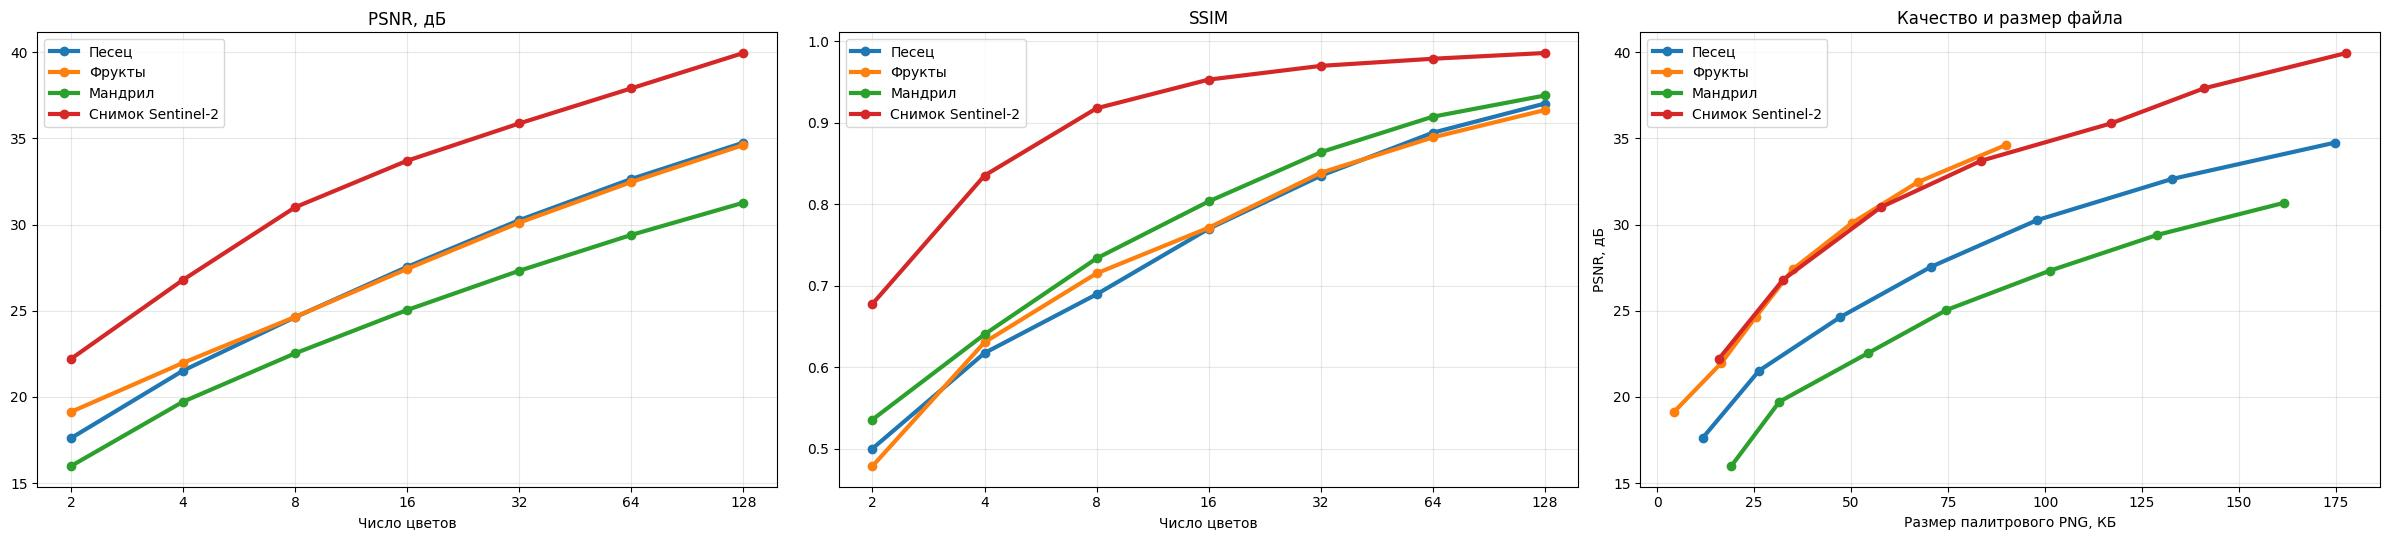

Изображение,Мандрил,Песец,Снимок Sentinel-2,Фрукты
Цветов,,,,
2,16.0,17.6,22.2,19.1
4,19.7,21.5,26.8,22.0
8,22.5,24.6,31.0,24.6
16,25.0,27.5,33.7,27.4
32,27.3,30.3,35.9,30.1
64,29.4,32.6,37.9,32.5
128,31.3,34.8,40.0,34.6


In [ ]:
K_RANGE = [2, 4, 8, 16, 32, 64, 128]
quality = []
for name, img in images.items():
    for k in K_RANGE:
        palette, indices = quantized[name][k] if k in K_SHOW else quantize(img, k)
        restored = palette[indices]
        quality.append({'Изображение': name, 'Цветов': k,
                        'PSNR, дБ': peak_signal_noise_ratio(img, restored),
                        'SSIM': structural_similarity(img, restored, channel_axis=2),
                        'Палитровый PNG, КБ': file_size_kb(to_palette_image(palette, indices), format='PNG', optimize=True)})
quality = pd.DataFrame(quality)

fig, axes = plt.subplots(1, 3, figsize=(24, 5.5))
for name, part in quality.groupby('Изображение', sort=False):
    axes[0].plot(part['Цветов'], part['PSNR, дБ'], 'o-', linewidth=3, label=name)
    axes[1].plot(part['Цветов'], part['SSIM'], 'o-', linewidth=3, label=name)
    axes[2].plot(part['Палитровый PNG, КБ'], part['PSNR, дБ'], 'o-', linewidth=3, label=name)
for ax, title in zip(axes, ['PSNR, дБ', 'SSIM', 'Качество и размер файла']):
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()
for ax in axes[:2]:
    ax.set_xscale('log', base=2)
    ax.set_xticks(K_RANGE, K_RANGE)
    ax.set_xlabel('Число цветов')
axes[2].set_xlabel('Размер палитрового PNG, КБ')
axes[2].set_ylabel('PSNR, дБ')
plt.tight_layout()
plt.show()

quality.pivot(index='Цветов', columns='Изображение', values='PSNR, дБ').round(1)

Оба показателя растут с числом цветов. Порог около 30 дБ PSNR, при котором искажения малозаметны, достигается при разном числе цветов: у спутникового снимка уже при 8 цветах (31,0 дБ), у песца и фруктов — при 32 цветах (30,3 и 30,1 дБ), у мандрила — только при 128 цветах (31,3 дБ). Мандрил сжимается хуже всех из-за мелкой разноцветной текстуры шерсти, снимок — лучше всех из-за узкой палитры оттенков. Оптимальное число цветов зависит от содержания изображения.

### **6.4. Сжатие многоканального снимка**

Та же идея применима к многоканальному снимку: вместо шести значений отражения в формате float32 (24 байта на пиксель) можно хранить номер кластера (1 байт) и таблицу центроидов. При восстановлении каждый пиксель получает средний спектр своего кластера. Оценим, сколько при этом теряется.

In [ ]:
rows = []
for k in [8, 16, 64, 256]:
    km = KMeans(n_clusters=k, n_init=1, random_state=0).fit(pixels[sample])
    restored = km.cluster_centers_[km.predict(pixels)]
    rmse = np.sqrt(((restored - pixels) ** 2).mean(axis=0))
    rows.append({'Кластеров': k,
                 'Исходный размер, МБ': pixels.size * 4 / 2 ** 20,
                 'Сжатый размер, МБ': (len(pixels) * 1 + k * len(BANDS) * 4) / 2 ** 20,
                 **{f'RMSE {b}': e for b, e in zip(BANDS, rmse)},
                 'Средняя отн. ошибка, %': 100 * (np.abs(restored - pixels).mean(axis=0) / pixels.mean(axis=0)).mean()})
pd.DataFrame(rows).round(4)

,Кластеров,"Исходный размер, МБ","Сжатый размер, МБ",RMSE B2,RMSE B3,RMSE B4,RMSE B8,RMSE B11,RMSE B12,"Средняя отн. ошибка, %"
0,8,42.0322,1.7515,0.0197,0.0209,0.0229,0.0327,0.0258,0.0257,16.672001
1,16,42.0322,1.7517,0.0121,0.0128,0.0144,0.0253,0.0195,0.0192,12.159500
2,64,42.0322,1.7528,0.0087,0.0089,0.0097,0.0144,0.0128,0.0124,8.343500
3,256,42.0322,1.7572,0.0065,0.0067,0.0072,0.0095,0.0089,0.0087,6.065200


Шесть каналов в формате float32 занимают 42 МБ, а номера кластеров (по байту на пиксель) вместе с таблицей центроидов — около 1,75 МБ, то есть в 24 раза меньше при любом числе кластеров до 256. Ошибка восстановления уменьшается с ростом числа кластеров: средняя относительная ошибка — 16,7% при 8 кластерах, 12,2% при 16, 8,3% при 64 и 6,1% при 256. Такое сжатие подходит для быстрого просмотра и визуализации, но не для точных расчётов: ошибки в несколько процентов в отражении искажают спектральные индексы.

### **Выводы по разделу 6:**

1. **K-средних** сжимает изображение, заменяя все цвета палитрой из $K$ средних цветов; число цветов задаёт баланс между размером и качеством
2. **Сохранять результат нужно в палитровом PNG**: в JPEG или обычном RGB-PNG сжатое изображение может весить столько же или больше исходного
3. **Палитровый PNG** в 3,5–24 раза меньше PNG без потерь; с исходным JPEG он выигрывает при небольшом числе цветов
4. **Качество при одном числе цветов** зависит от содержания изображения: спутниковому фрагменту хватает 8 цветов для PSNR выше 30 дБ, мандрилу с мелкой текстурой — 128
5. **Многоканальный снимок** можно хранить в 24 раза компактнее, но с ошибкой в несколько процентов

---

## **Заключение**

В рамках данного блокнота были освоены основные концепции кластеризации и её применения к изображениям:

1. **Теоретические основы:**
   - Отличие кластеризации (обучение без учителя) от классификации
   - Алгоритм K-средних: назначение объектов ближайшему центроиду, пересчёт центроидов, минимизация суммы квадратов расстояний
   - Масштабирование признаков и выбор числа кластеров методом локтя и коэффициентом силуэта

2. **Анализ спутникового снимка:**
   - Кластеризация композита Sentinel-2 локально (`scikit-learn`) и на серверах Google Earth Engine
   - Интерпретация кластеров по спектральным профилям и сравнению с готовой картой классификации
   - Поиск объектов, отсутствующих в легенде готовых карт: малые кластеры и пиксели, далёкие от всех центроидов

3. **Сжатие изображений:**
   - Цветовая квантизация фотографий и снимка методом K-средних
   - Правильное сохранение в палитровом формате и оценка качества метриками PSNR и SSIM

### **Возможные направления применения полученных знаний**

**1. Обзор и разведка территорий:**
- Быстрое разделение снимка на однородные участки без эталонных карт
- Выбор классов и мест для сбора обучающих примеров перед классификацией

**2. Поиск необычных объектов:**
- Обнаружение объектов, отсутствующих в легендах готовых карт: складские и промышленные комплексы, карьеры, свалки, стройплощадки
- Поиск редких поверхностей по расстоянию до центроидов: новые постройки, разливы, аномальные участки растительности

**3. Мониторинг изменений:**
- Сравнение кластеров разных лет и выявление участков, сменивших спектральную группу

**4. Обработка и хранение изображений:**
- Цветовая квантизация для веб-графики, иконок, схем и карт
- Компактное хранение и передача многоканальных снимков с контролируемой ошибкой